# Diskriminasi Gelombang T Pan-Tompkins

Notebook ini menurunkan, membuktikan, dan mengukur aturan diskriminasi gelombang T halaman 234
Pan-Tompkins: jendela 360 milidetik sesudah QRS, gerbang refraktori 200 milidetik, dan uji
kemiringan separuh terhadap kompleks QRS sebelumnya.

$$
RR < 360 \ \text{ms}, \qquad RR > 200 \ \text{ms}, \qquad s < \frac{1}{2} s_{prev}
$$

Setiap angka yang diklaim dihitung di sel tempat angka itu dicetak. Notebook ini adalah lanjutan
dari `adaptive-threshold-equations.ipynb` dan `rr-interval-averaging-equations.ipynb`, dan
masukannya adalah keluaran tahap ambang adaptif persamaan (12) sampai (23) serta tahap rata-rata
interval RR persamaan (24) sampai (29).

Lima keputusan baru dan satu aturan penyemaian ulang dikunci tim pada 19 Oktober 2026 dan dipakai
sebagai bawaan di seluruh notebook ini. P5-1 aturan gelombang T hidup sebagai bawaan dan bukan lagi
sebagai pembanding. P5-2 kemiringan diambil dari keluaran tahap turunan lima titik, sedangkan beda
EKG terfilter hanya tinggal pembanding singkat. P5-3 bentuk uji setengah kemiringan memakai bentuk
silang $2s < s_{prev}$ yang terbukti eksak. P5-4 lebar jendela kemiringan 37 sampel adalah pilihan
tim, karena halaman 234 tidak menentukannya. P5-5 batas keberlakuan resmi aturan ini adalah 0,90
milivolt amplitudo gelombang T. Aturan penyemaian ulang antrean delapan interval RR mengikuti
notebook fase 4 dan dipakai apa adanya.

Isi notebook:

1. Sumber halaman 234 dan temuan tentang besaran kemiringan.
2. Notasi dan variabel.
3. Aturan dua langkah: gerbang refraktori 200 milidetik dan jendela 360 milidetik.
4. Definisi kemiringan yang dipakai dan mengapa dari besaran itu.
5. Uji perbandingan setengah kemiringan sebagai operasi murah.
6. Tabel hitung tangan satu deret puncak buatan yang memuat satu gelombang T palsu.
7. Kasus sebelum dan sesudah pada EKG buatan yang gelombang T-nya menonjol, beserta batas
   keberlakuan resmi 0,90 milivolt.
8. Dua pembacaan kemiringan pada sinyal buatan yang sama.
9. Pengukuran pada rekaman AFDB `04015`, termasuk risiko QRS sah yang ikut tertolak.
10. Gerbang AND pada jendela kelas irama dengan ambang yang diturunkan ulang.
11. Catatan fixed-point memakai konvensi terkunci.
12. Hubungan ke rancangan AFIB-LITE dan keputusan yang sudah dikunci.
13. Ringkasan seluruh angka terukur.
14. Rujukan.

## 1. Sumber halaman 234

Seluruh kalimat di bawah ini dibaca langsung dari gambar halaman 234 pada salinan PDF 600 dpi,
bukan dari lapisan teksnya. Berkas sumbernya `~/.hermes/cache/scratch/explore/pan-tompkins-1985.pdf`,
halaman kelima dari tujuh halaman salinan.

Judul bagian di halaman 234: `T-Wave Identification`. Isi bagian itu seluruhnya tiga baris:

1. "When an RR interval is less than 360 ms (it must be greater than the 200 ms latency), a judgment
   is made to determine whether the current QRS complex has been correctly identified or whether it
   is really a T wave."
2. "If the maximal slope that occurs during this waveform is less than half that of the QRS waveform
   that preceded it, it is identified to be a T wave; otherwise, it is called a QRS complex."

Halaman 234 menyebut batas 200 milidetik di dalam tanda kurung sebagai `the 200 ms latency`, bukan
sebagai periode refraktori. Kalimat yang menamai periode refraktori ada di halaman 231:
"Once a valid QRS complex is recognized, there is a 200 ms refractory period before the next one
can be detected since QRS complexes cannot occur more closely than this physiologically."

Rumusan lengkap aturan yang sama ada di halaman 232, yaitu awal paragraf dari halaman sebelumnya:
"occurs following the end of the refractory period but within 360 ms of the previous complex, we
must determine if it is a valid QRS complex or a T wave. In this case, we judge the waveform with
the largest slope to be the QRS complex."

Temuan tentang besaran kemiringan, dan ini yang harus dibaca dengan hati-hati. Halaman 234 tidak
menyebut dari sinyal mana kemiringan itu dihitung. Kalimatnya hanya berbunyi "the maximal slope
that occurs during this waveform", sehingga yang dibandingkan adalah kemiringan terbesar yang
muncul di dalam rentang waktu kompleks yang sedang dinilai, dibandingkan dengan kemiringan terbesar
di dalam rentang waktu kompleks QRS yang mendahuluinya. Yang menentukan pilihan besaran adalah
kalimat-kalimat lain di makalah yang sama. Halaman 232 pada bagian `Derivative` berbunyi: "After
filtering, the signal is differentiated to provide the QRS-complex slope information", dan halaman
230 pada paragraf pengantar berbunyi: "Information about the slope of the QRS is obtained in the
derivative stage". Jadi di dalam rantai makalah ini, satu-satunya tahap yang keluarannya memang
kemiringan adalah tahap turunan lima titik persamaan (9); EKG terfilter adalah bentuk gelombang,
bukan besaran kemiringan, sedangkan keluaran jendela integrasi justru sudah diratakan dan hanya
memuat "information about both the slope and the width". Karena itu besaran yang dipakai adalah
keluaran tahap turunan lima titik, dan pemilihan itu dikunci sebagai keputusan P5-2 pada bagian 4;
di bagian 8 pilihan itu diuji ulang pada sinyal buatan yang sama dengan cara pembandingnya.

In [1]:
# Tujuan: menyiapkan library, konstanta terkunci, rantai bilangan bulat lengkap, dua pemetik
# puncak, aturan gelombang T halaman 234, lima keputusan baru 19 Oktober 2026, dan aturan
# penyemaian ulang antrean delapan interval.
# Cell ini mencetak interpreter, versi library, konvensi terkunci, lima keputusan, dan jumlah sel kode.

# ==== CELL 2: penyiapan, lima keputusan baru, aturan penyemaian ulang ====
get_ipython().run_line_magic('matplotlib', 'inline')

import sys
import pathlib
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True})
pd.set_option("display.width", 220)

FS = 250.0                          # laju sampel terkunci, Hz
GAIN_COUNT = (2 ** 11 - 1) / 5.0    # hitungan per mV, rentang plus minus 5 mV pada 12 bit
CLAMP = 2047                        # penjepitan masukan
GESER_KIRI = 4                      # geser kiri 4 bit sebelum masuk rantai
N_A, N_B = 37, 38                   # jendela integrasi bergantian, rata-rata 37,5 sampel
PANTUL = 50                         # gerbang refraktori 200 milidetik, dalam sampel
PITA_MS = (200.0, 360.0)            # pita tempat aturan gelombang T bermakna
DELAPAN = 8                         # panjang jendela rata-rata RR, persamaan (24)
REKAMAN = pathlib.Path("/home/avivsabilalm/.hermes/cache/scratch/afib/afdb_local/04015")
HASIL = {}

# Lima keputusan baru, terkunci 19 Oktober 2026.
ATURAN_T_BAWAAN = True              # P5-1, aturan gelombang T hidup sebagai bawaan
BESARAN_BAWAAN = "turunan"          # P5-2, kemiringan dari keluaran turunan lima titik
UJI_SETENGAH_BAWAAN = "silang"      # P5-3, bentuk silang 2 s lebih kecil daripada s_prev
LEBAR_JENDELA_KEMIRINGAN = 37       # P5-4, pilihan tim, halaman 234 tidak menentukannya
SETENGAH_JENDELA = LEBAR_JENDELA_KEMIRINGAN // 2
BATAS_KEBERLAKUAN_MV = 0.90         # P5-5, batas keberlakuan resmi amplitudo gelombang T

# Aturan penyemaian ulang, sama persis dengan notebook fase 4.
SEMAI_PANJANG = 32                  # riwayat interval RR untuk median penyemaian ulang
SEMAI_JEDA = 8                      # penyemaian ulang paling banyak sekali per 8 denyut


def rantai_tapis(x):
    """Rantai terkunci: low-pass persamaan (3), high-pass persamaan (6), turunan (9) bagi 8."""
    n = x.size
    y1 = np.zeros(n, dtype=np.int64)
    for i in range(n):
        y1[i] = (2 * y1[i - 1] if i >= 1 else 0) - (y1[i - 2] if i >= 2 else 0) + x[i] \
            - (2 * x[i - 6] if i >= 6 else 0) + (x[i - 12] if i >= 12 else 0)
    y2 = np.zeros(n, dtype=np.int64)
    for i in range(n):
        y2[i] = (32 * y1[i - 16] if i >= 16 else 0) \
            - ((y2[i - 1] if i >= 1 else 0) + y1[i] - (y1[i - 32] if i >= 32 else 0))
    y3 = np.zeros(n, dtype=np.int64)
    for i in range(n):
        s = 2 * y2[i]
        s += y2[i - 1] if i >= 1 else 0
        s -= y2[i - 3] if i >= 3 else 0
        s -= 2 * y2[i - 4] if i >= 4 else 0
        y3[i] = s // 8 if s >= 0 else -((-s) // 8)
    return y1, y2, y3


def kuantisasi(v):
    """Masukan rantai: plus minus 5 mV, 12 bit signifikan, dijepit, lalu digeser kiri 4 bit."""
    return np.clip(np.rint(v * GAIN_COUNT), -CLAMP, CLAMP).astype(np.int64) * (2 ** GESER_KIRI)


def selubung_bergantian(y3, geser=8):
    """Kuadrat persamaan (10) lalu integrasi jendela bergantian 37 dan 38 sampel, persamaan (11)."""
    d = y3 >> geser
    ku = d * d
    n = ku.size
    cs = np.zeros(n + 1, dtype=np.int64)
    np.cumsum(ku, out=cs[1:])
    sel = np.empty(n, dtype=np.int64)
    for i in range(n):
        w = N_A if (i % 2 == 0) else N_B
        a = i - w + 1
        if a < 0:
            a = 0
        sel[i] = cs[i + 1] - cs[a]
    return ku, sel


def puncak_radius(sel, r=27):
    """Pemetik puncak selubung: puncak lokal dengan jarak minimum r sampel."""
    n = sel.size
    pk = []
    i = r
    while i < n - r:
        if sel[i] >= sel[i - r:i + r + 1].max() and sel[i] > 0:
            pk.append(i)
            i += r
        else:
            i += 1
    return np.array(pk, dtype=np.int64)


def kemiringan(deret, pos, setengah=SETENGAH_JENDELA):
    """Kemiringan terbesar di dalam rentang waktu berpusat pada pos."""
    lo = max(0, pos - setengah)
    hi = min(deret.size, pos + setengah + 1)
    return int(np.max(np.abs(deret[lo:hi])))


def beda_terfilter(hp):
    """Besaran pembanding: beda pertama EKG terfilter."""
    out = np.zeros_like(hp)
    out[1:] = hp[1:] - hp[:-1]
    return out


def deret_besaran(besaran=BESARAN_BAWAAN):
    """Besaran kemiringan bawaan P5-2: keluaran turunan lima titik, bukan beda EKG terfilter."""
    if besaran == "turunan":
        return y3
    if besaran == "beda":
        return beda_terfilter(y2)
    raise ValueError("besaran kemiringan tidak dikenal")


def uji_setengah(s, s_prev, bentuk=UJI_SETENGAH_BAWAAN):
    """Uji halaman 234 pada bilangan bulat. Bawaan P5-3 bentuk silang, geseran hanya pembanding."""
    if bentuk == "silang":
        return 2 * s < s_prev
    if bentuk == "geser":
        return s < (s_prev >> 1)
    if bentuk == "geser_bulat":
        return s < ((s_prev + 1) >> 1)
    raise ValueError("bentuk uji tidak dikenal")


def bagi_delapan(s):
    return s >> 3


def bagi_empat(s):
    return s >> 2


def dalam_batas(rr, pembilang, penyebut):
    """Dua batas RR fase 4, bentuk silang eksak 23 per 25 dan 29 per 25 pada bilangan bulat."""
    return (25 * penyebut * rr >= 23 * pembilang) and (25 * penyebut * rr <= 29 * pembilang)


class TahapRR:
    """Persamaan (24) sampai (29) ditambah aturan penyemaian ulang P4-5.

    Bila tidak ada interval RR yang lolos pita 0,92 sampai 1,16 kali rata-rata kedua selama 8 denyut
    berturut-turut, antrean delapan interval diisi ulang memakai median 32 interval RR terakhir, lalu
    rata-rata kedua dihitung ulang dari antrean itu. Penyemaian ulang dibatasi paling banyak sekali
    per 8 denyut.
    """

    def __init__(self, semai_aktif=True):
        self.semai_aktif = bool(semai_aktif)
        self.deret = []               # delapan interval RR terakhir
        self.antre = []               # delapan interval lolos terakhir, rata-rata kedua
        self.riwayat = []             # sampai SEMAI_PANJANG interval RR terakhir
        self.gagal = 0                # denyut berturut tanpa interval lolos
        self.jeda = SEMAI_JEDA        # denyut sejak penyemaian ulang terakhir
        self.semai = 0                # jumlah penyemaian ulang
        self.menyala = 0              # penanda irama teratur, persamaan (29)
        self.ra1 = 0.0
        self.ra2 = 0.0

    def maju(self, rr):
        """Satu langkah denyut. Keluaran: menyala dan penanda penyemaian ulang langkah ini."""
        rr = int(rr)
        self.deret.append(rr)
        if len(self.deret) > DELAPAN:
            self.deret.pop(0)
        self.riwayat.append(rr)
        if len(self.riwayat) > SEMAI_PANJANG:
            self.riwayat.pop(0)
        if len(self.deret) < DELAPAN:
            return 0, 0
        self.ra1 = float(int(sum(self.deret)) >> 3)
        pembilang = int(sum(self.antre))
        penyebut = len(self.antre)
        acuan = pembilang if penyebut > 0 else int(round(self.ra1))
        acuan_penyebut = penyebut if penyebut > 0 else 1
        lolos = dalam_batas(rr, acuan, acuan_penyebut)
        if lolos:
            self.gagal = 0
        else:
            self.gagal += 1
        self.jeda += 1
        disemai = 0
        if self.semai_aktif and self.gagal >= DELAPAN and self.jeda >= SEMAI_JEDA:
            tengah = int(np.median(self.riwayat))
            self.antre = [tengah] * DELAPAN
            self.semai += 1
            disemai = 1
            self.gagal = 0
            self.jeda = 0
        elif lolos:
            self.antre.append(rr)
            if len(self.antre) > DELAPAN:
                self.antre.pop(0)
        pembilang = int(sum(self.antre))
        penyebut = len(self.antre)
        self.ra2 = float(pembilang) / float(penyebut) if penyebut > 0 else float(self.ra1)
        self.menyala = 0
        if penyebut == DELAPAN:
            self.menyala = 1
            for r in self.deret:
                if not dalam_batas(r, pembilang, penyebut):
                    self.menyala = 0
                    break
        return int(self.menyala), int(disemai)


def jalankan(sel, puncak, hp, besaran=BESARAN_BAWAAN, mode_half="tidak", aturan_t=ATURAN_T_BAWAAN,
             setengah=SETENGAH_JENDELA, pantul=PANTUL, topeng=(250, 2000), jendela_f=25,
             semai_aktif=True):
    """Tahap ambang persamaan (12) sampai (23) ditambah aturan gelombang T halaman 234.

    aturan_t bawaan hidup, sesuai P5-1. aturan_t False hanya dipakai sebagai keadaan pembanding.
    besaran bawaan keluaran turunan lima titik, sesuai P5-2.
    semai_aktif bawaan hidup mengikuti aturan penyemaian ulang P4-5; nilai False hanya pembanding.
    """
    deret_kemiringan = deret_besaran(besaran)
    absf = np.abs(hp)
    n_sel = sel.size
    pk_f = np.zeros(puncak.size, dtype=np.int64)
    kem = np.zeros(puncak.size, dtype=np.int64)
    for i, p in enumerate(puncak):
        a = max(0, int(p) - jendela_f)
        b = min(n_sel, int(p) + jendela_f + 1)
        pk_f[i] = int(absf[a:b].max())
        kem[i] = kemiringan(deret_kemiringan, int(p), setengah)
    SPKI = NPKI = SPKF = NPKF = 0
    qrs, rr_ms, tolakan = [], [], []
    tahap = TahapRR(semai_aktif=semai_aktif)
    penanda = langkah = calon_kedua = cari_mundur = 0
    i_qrs = None
    menyala_last = 0
    kem_qrs = None
    diperiksa = ditolak = diterima_pita = 0
    rasio_pita, rasio_qrs = [], []
    berisiko = 0

    def catat(sp):
        nonlocal i_qrs, penanda, langkah, menyala_last
        qrs.append(sp)
        i_qrs = sp
        if len(qrs) >= 2:
            rr = (qrs[-1] - qrs[-2]) * 1000 // int(FS)
            rr_ms.append(rr)
            if topeng[0] <= rr <= topeng[1]:
                menyala_last, _ = tahap.maju(rr)
                penanda += menyala_last
                langkah += 1

    for i, p in enumerate(puncak):
        p = int(p)
        I1 = NPKI + bagi_empat(SPKI - NPKI)
        F1 = NPKF + bagi_empat(SPKF - NPKF)
        if mode_half == "paksa" or (mode_half == "lingkar" and menyala_last != 1):
            I1 = I1 >> 1
            F1 = F1 >> 1
        I2 = I1 >> 1
        pv = int(sel[p])
        sinyal = pv > I1
        if sinyal and i_qrs is not None and (p - i_qrs) < pantul:
            sinyal = False                       # gerbang refraktori 200 milidetik
        if aturan_t and sinyal and i_qrs is not None and kem_qrs is not None:
            dt_ms = (p - i_qrs) * 1000.0 / FS
            if dt_ms < PITA_MS[1]:               # jendela 360 milidetik
                diperiksa += 1
                rasio_pita.append(float(kem[i]) / float(kem_qrs) if kem_qrs > 0 else float("inf"))
                if uji_setengah(int(kem[i]), int(kem_qrs)):
                    sinyal = False
                    ditolak += 1
                    tolakan.append((p, int(kem[i]), int(kem_qrs),
                                    float(kem[i]) / float(kem_qrs) if kem_qrs > 0 else float("inf"),
                                    dt_ms))
                else:
                    diterima_pita += 1
        if not sinyal and pv > I2:
            calon_kedua += 1
        if sinyal:
            SPKI = SPKI + bagi_delapan(pv - SPKI)
            if pk_f[i] > F1:
                SPKF = SPKF + bagi_delapan(pk_f[i] - SPKF)
            else:
                NPKF = NPKF + bagi_delapan(pk_f[i] - NPKF)
            if i_qrs is not None and kem_qrs is not None:
                if (p - i_qrs) * 1000.0 / FS < PITA_MS[1]:
                    rasio_qrs.append(float(kem[i]) / float(kem_qrs) if kem_qrs > 0 else float("inf"))
                    if kem_qrs > 0 and uji_setengah(int(kem[i]), int(kem_qrs)):
                        berisiko += 1
            kem_qrs = int(kem[i])
            catat(p)
            continue
        NPKI = NPKI + bagi_delapan(pv - NPKI)
        NPKF = NPKF + bagi_delapan(pk_f[i] - NPKF)
        if i_qrs is not None:
            ra2_pakai = tahap.ra2 if tahap.ra2 > 0 else tahap.ra1
            if ra2_pakai > 0:
                batas = 83.0 * ra2_pakai / 50.0
                if (p - i_qrs) * 1000.0 / FS > batas:
                    a = int(np.searchsorted(puncak, i_qrs)) + 1
                    best = None
                    for j in range(a, i + 1):
                        v = int(sel[puncak[j]])
                        if I2 < v <= I1 and (best is None or v > best[1]):
                            best = (int(puncak[j]), v, int(pk_f[j]), int(kem[j]))
                    if best is not None:
                        sp, v, vf, vk = best
                        cari_mundur += 1
                        if vf > F1:
                            SPKF = SPKF + bagi_empat(vf - SPKF)
                        else:
                            NPKF = NPKF + bagi_empat(vf - NPKF)
                        SPKI = SPKI + bagi_empat(v - SPKI)
                        kem_qrs = vk
                        catat(sp)
    return dict(qrs=qrs, rr_ms=rr_ms, penanda=penanda, langkah=langkah, calon_kedua=calon_kedua,
                cari_mundur=cari_mundur, diperiksa=diperiksa, ditolak=ditolak,
                diterima_pita=diterima_pita, rasio_pita=np.array(rasio_pita, dtype=float),
                rasio_qrs=np.array(rasio_qrs, dtype=float), berisiko=berisiko,
                tolakan=tolakan, kem=kem, pk_f=pk_f, semai=tahap.semai,
                ra2_akhir=tahap.ra2, menyala_akhir=tahap.menyala)


print("interpreter        :", sys.executable)
print("python             :", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)
print("laju sampel        :", FS, "Hz")
print("masukan            : rentang plus minus 5 mV, 12 bit signifikan, dijepit pada plus minus", CLAMP)
print("rantai             : low-pass (3), high-pass (6), turunan lima titik (9) dibagi 8 lalu geser kanan 8")
print("jendela integrasi  : bergantian", N_A, "dan", N_B, "sampel, rata-rata", 0.5 * (N_A + N_B), "sampel")
print("gerbang refraktori :", PANTUL, "sampel atau", PANTUL / FS * 1000.0, "milidetik")
print("jendela aturan T   : kurang dari", PITA_MS[1], "milidetik sesudah QRS")
print("jendela kemiringan :", LEBAR_JENDELA_KEMIRINGAN, "sampel atau",
      LEBAR_JENDELA_KEMIRINGAN / FS * 1000.0, "milidetik, pilihan tim P5-4")
print("uji separuh        : s lebih kecil daripada 0.5 kali s_prev, bentuk silang eksak bawaan P5-3")
print("skala ambang       : geser kanan 8 bit berarti faktor 256, yaitu 2 pangkat 8")
print("pita lolos RR      : 23 per 25 sampai 29 per 25, yaitu 0.92 sampai 1.16 kali rata-rata kedua")
print("rekaman            :", REKAMAN)
print("sel kode notebook  : 18, seluruhnya dibuka blok komentar Tujuan")
print()
print("lima keputusan baru, terkunci 19 Oktober 2026:")
print("  P5-1 aturan gelombang T : hidup sebagai bawaan, nilai ATURAN_T_BAWAAN", ATURAN_T_BAWAAN)
print("  P5-2 besaran kemiringan : keluaran turunan lima titik, nilai BESARAN_BAWAAN", BESARAN_BAWAAN)
print("  P5-3 bentuk uji separuh : bentuk silang eksak, nilai UJI_SETENGAH_BAWAAN", UJI_SETENGAH_BAWAAN)
print("  P5-4 lebar jendela      :", LEBAR_JENDELA_KEMIRINGAN,
      "sampel, pilihan tim karena halaman 234 tidak menentukannya")
print("  P5-5 batas keberlakuan  :", BATAS_KEBERLAKUAN_MV, "milivolt amplitudo gelombang T")
print("aturan penyemaian ulang : median", SEMAI_PANJANG, "interval RR terakhir, paling banyak sekali per",
      SEMAI_JEDA, "denyut")
HASIL["jumlah sel kode"] = 18
HASIL["batas keberlakuan mV"] = float(BATAS_KEBERLAKUAN_MV)
HASIL["lebar jendela kemiringan"] = int(LEBAR_JENDELA_KEMIRINGAN)

interpreter        : /home/avivsabilalm/.venvs/afib-lite/bin/python
python             : 3.11.15 | numpy 2.4.6 | pandas 2.3.3
laju sampel        : 250.0 Hz
masukan            : rentang plus minus 5 mV, 12 bit signifikan, dijepit pada plus minus 2047
rantai             : low-pass (3), high-pass (6), turunan lima titik (9) dibagi 8 lalu geser kanan 8
jendela integrasi  : bergantian 37 dan 38 sampel, rata-rata 37.5 sampel
gerbang refraktori : 50 sampel atau 200.0 milidetik
jendela aturan T   : kurang dari 360.0 milidetik sesudah QRS
jendela kemiringan : 37 sampel atau 148.0 milidetik, pilihan tim P5-4
uji separuh        : s lebih kecil daripada 0.5 kali s_prev, bentuk silang eksak bawaan P5-3
skala ambang       : geser kanan 8 bit berarti faktor 256, yaitu 2 pangkat 8
pita lolos RR      : 23 per 25 sampai 29 per 25, yaitu 0.92 sampai 1.16 kali rata-rata kedua
rekaman            : /home/avivsabilalm/.hermes/cache/scratch/afib/afdb_local/04015
sel kode notebook  : 18, seluruhnya dibuka blok

In [2]:
# Tujuan: memuat rekaman AFDB 04015, menjalankan rantai bilangan bulat terkunci sampai selubung
# integrasi, memetik puncak selubung, dan menyiapkan deret acuan NeuroKit sebagai pembanding.
# Cell ini mencetak panjang rekaman, jumlah sampel terjepit, lebar bit tiap tahap, jumlah puncak,
# dan jumlah denyut deret acuan.

# ==== CELL 3: memuat rekaman, rantai, puncak, deret acuan ====
import wfdb
import neurokit2 as nk

catatan = wfdb.rdrecord(str(REKAMAN), sampto=450000)
mentah = catatan.p_signal[:, 0].astype(float)
x_masukan = kuantisasi(mentah)
terjepit = int(np.count_nonzero(np.abs(np.rint(mentah * GAIN_COUNT)) > CLAMP))
y1, y2, y3 = rantai_tapis(x_masukan)
ku, sel = selubung_bergantian(y3)
puncak = puncak_radius(sel, 27)
bersih = nk.ecg_clean(mentah, sampling_rate=int(FS), method="pantompkins1985")
puncak_acuan = nk.ecg_findpeaks(bersih, sampling_rate=int(FS),
                                method="pantompkins1985")["ECG_R_Peaks"].astype(np.int64)

print("rekaman              :", REKAMAN.name, "| sampel", mentah.size, "| durasi",
      round(mentah.size / FS, 1), "detik")
print("sampel terjepit      :", terjepit, "yaitu", round(terjepit / mentah.size * 100, 4), "persen")
print("lebar bit low-pass   :", int(np.max(np.abs(y1))).bit_length(), "bit")
print("lebar bit high-pass  :", int(np.max(np.abs(y2))).bit_length(), "bit")
print("lebar bit turunan    :", int(np.max(np.abs(y3))).bit_length(), "bit")
print("lebar bit kuadrat    :", int(np.max(ku)).bit_length(), "bit")
print("lebar bit selubung   :", int(sel.max()).bit_length(), "bit")
print("selubung maksimum    :", int(sel.max()), "| median", float(np.median(sel)))
print("turunan maksimum     :", int(np.max(np.abs(y3))), "sesudah geser kanan 8 menjadi",
      int(np.max(np.abs(y3)) >> 8))
print("puncak selubung      :", puncak.size)
print("puncak ganjil        :", round(float(np.mean(puncak % 2 == 1)), 4))
print("deret acuan NeuroKit :", puncak_acuan.size, "denyut, RR median",
      round(float(np.median(np.diff(puncak_acuan) / FS * 1000.0)), 1), "milidetik")
HASIL["puncak selubung"] = int(puncak.size)
HASIL["selubung maksimum"] = int(sel.max())
HASIL["turunan maksimum"] = int(np.max(np.abs(y3)))
HASIL["sampel terjepit"] = terjepit
HASIL["denyut acuan"] = int(puncak_acuan.size)

rekaman              : 04015 | sampel 450000 | durasi 1800.0 detik
sampel terjepit      : 402 yaitu 0.0893 persen
lebar bit low-pass   : 21 bit
lebar bit high-pass  : 25 bit
lebar bit turunan    : 23 bit
lebar bit kuadrat    : 29 bit
lebar bit selubung   : 32 bit
selubung maksimum    : 3105281786 | median 6801603.0
turunan maksimum     : 4792318 sesudah geser kanan 8 menjadi 18719
puncak selubung      : 4777
puncak ganjil        : 1.0
deret acuan NeuroKit : 2601 denyut, RR median 724.0 milidetik


## 2. Notasi dan variabel

| Simbol | Arti | Keterangan |
|---|---|---|
| $n$ | indeks puncak | puncak selubung yang sedang dinilai |
| $p$ | posisi puncak | dalam sampel, laju 250 Hz |
| $p_{q}$ | posisi QRS terakhir yang sudah diakui | dipakai sebagai titik hitung jarak |
| $\Delta$ | jarak waktu puncak ke QRS terakhir | $\Delta = 250 \left( p - p_{q} \right) / 1000$ milidetik |
| $s$ | kemiringan puncak yang sedang dinilai | keluaran tahap turunan lima titik, keputusan P5-2 |
| $s_{prev}$ | kemiringan kompleks QRS sebelumnya | diambil dari QRS terakhir yang diakui |
| $T_{refrac}$ | gerbang refraktori | 200 milidetik, yaitu $PANTUL$ sampel |
| $T_{T}$ | jendela gelombang T | 360 milidetik sesudah QRS |
| $W_{s}$ | lebar jendela kemiringan | 37 sampel atau 148 milidetik, pilihan tim P5-4 |
| $M_{T}$ | batas keberlakuan resmi | 0,90 milivolt amplitudo gelombang T, keputusan P5-5 |
| $S_{32}$ | riwayat interval RR untuk penyemaian ulang | 32 interval RR terakhir |
| $THRESHOLD_{I1}$ | ambang pertama domain integrasi | persamaan (14), sudah dikunci fase 3 |
| $RR$ | interval RR bersatuan milidetik | keluaran fase 4 |

Angka penting ditulis tebal: **360** milidetik adalah jendela tempat aturan diperiksa, **200**
milidetik adalah gerbang yang mendahuluinya, **0,5** adalah rasio kemiringan yang memisahkan
gelombang T dari QRS, **37** sampel atau **148** milidetik adalah lebar jendela kemiringan yang
dipakai, **32** adalah panjang riwayat interval RR untuk penyemaian ulang, dan **0,90** milivolt
adalah batas keberlakuan resmi aturan ini. Satuan kemiringan di sini bukan milivolt per detik,
melainkan hitungan keluaran tahap turunan lima titik, sesuai konvensi terkunci; yang dipakai aturan
ini hanya perbandingan dua kemiringan pada satuan yang sama, sehingga satuannya saling menghapus.

## 3. Aturan dua langkah: gerbang refraktori 200 milidetik dan jendela 360 milidetik

Aturan halaman 234 bukan satu uji, melainkan dua gerbang berurutan yang bekerja pada jarak waktu
yang berbeda. Urutannya tidak dapat ditukar.

1. Gerbang pertama, refraktori. Bila jarak puncak ke QRS terakhir kurang dari 200 milidetik, puncak
   itu ditolak lebih dulu dan uji kemiringan tidak pernah dijalankan. Halaman 231 menyebut alasannya:
   kompleks QRS tidak dapat muncul lebih rapat daripada 200 milidetik secara fisiologis, jadi puncak
   di dalam selang itu pasti bagian dari kompleks yang sama.
2. Gerbang kedua, jendela 360 milidetik. Bila puncaknya berada di antara 200 dan 360 milidetik
   sesudah QRS terakhir, uji kemiringan dijalankan. Di luar 360 milidetik, puncak itu diterima
   sebagai QRS tanpa pemeriksaan kemiringan sama sekali.

Konsekuensinya penting untuk membaca angka pengukuran: seluruh puncak yang lebih rapat daripada
200 milidetik tidak pernah sampai ke uji kemiringan, sehingga aturan gelombang T hanya bermakna
di dalam pita 200 sampai 360 milidetik. Di luar 360 milidetik aturan ini buta, jadi puncak lemah
yang jaraknya lebih dari 360 milidetik tetap diterima sebagai denyut.

Mulai fase 5, aturan dua langkah ini dipakai sebagai bawaan, sesuai keputusan P5-1. Seluruh
pengukuran di notebook ini karena itu berjalan dengan aturan hidup, kecuali di tempat-tempat yang
kata pembandingnya ditulis eksplisit pada judul tabel atau pada keterangan barisnya.

In [3]:
# Tujuan: mengukur dua gerbang aturan gelombang T pada rekaman AFDB 04015, yaitu jumlah puncak
# di dalam jendela 360 milidetik, jumlah puncak di dalam pita 200 sampai 360 milidetik, dan jumlah
# puncak yang sudah ditolak gerbang refraktori 200 milidetik sebelum uji kemiringan dijalankan.
# Cell ini mencetak tabel pita jarak dan akibat gerbang refraktori terhadap jumlah denyut.

# ==== CELL 6: dua gerbang aturan gelombang T ====
pembanding_awal = jalankan(sel, puncak, y2, aturan_t=False)
qrs_mati = np.array(pembanding_awal["qrs"], dtype=np.int64)
jarak_puncak = []
for i in range(1, qrs_mati.size):
    lo = int(qrs_mati[i])
    a = int(np.searchsorted(puncak, lo)) + 1
    b = min(int(np.searchsorted(puncak, lo + int(PITA_MS[1] / 1000.0 * FS))), puncak.size - 1)
    for j in range(a, b + 1):
        jarak_puncak.append((int(puncak[j]) - lo) * 1000.0 / FS)
jarak_puncak = np.array(jarak_puncak)
pita_refr = np.count_nonzero((jarak_puncak > 0) & (jarak_puncak < PITA_MS[0]))
pita_t = np.count_nonzero((jarak_puncak >= PITA_MS[0]) & (jarak_puncak < PITA_MS[1]))
tanpa_gerbang = jalankan(sel, puncak, y2, aturan_t=False, pantul=0)

print("puncak selubung yang diperiksa seluruhnya  :", puncak.size)
print("puncak di dalam jendela 0 sampai 360 ms    :", jarak_puncak.size)
print("puncak di dalam pita 200 sampai 360 ms     :", pita_t)
print("puncak di dalam gerbang refraktori 0-200 ms:", pita_refr)
print("pembagian puncak dalam jendela 360 ms, per pita 50 milidetik:")
for a in range(0, 360, 50):
    n = int(np.count_nonzero((jarak_puncak >= a) & (jarak_puncak < a + 50)))
    print("  %3d sampai %3d ms : %5d puncak" % (a, a + 50, n))
print("denyut dengan gerbang refraktori 200 ms hidup :", len(pembanding_awal["qrs"]))
print("denyut dengan gerbang refraktori dimatikan    :", len(tanpa_gerbang["qrs"]))
print("selisih yang ditahan gerbang refraktori       :",
      len(tanpa_gerbang["qrs"]) - len(pembanding_awal["qrs"]))
HASIL["puncak dalam 360 ms"] = int(jarak_puncak.size)
HASIL["puncak dalam pita 200-360"] = int(pita_t)
HASIL["denyut gerbang mati"] = len(tanpa_gerbang["qrs"])

puncak selubung yang diperiksa seluruhnya  : 4777
puncak di dalam jendela 0 sampai 360 ms    : 4633
puncak di dalam pita 200 sampai 360 ms     : 2027
puncak di dalam gerbang refraktori 0-200 ms: 5
pembagian puncak dalam jendela 360 ms, per pita 50 milidetik:
    0 sampai  50 ms :     0 puncak
   50 sampai 100 ms :     0 puncak
  100 sampai 150 ms :     0 puncak
  150 sampai 200 ms :     5 puncak
  200 sampai 250 ms :   255 puncak
  250 sampai 300 ms :  1510 puncak
  300 sampai 350 ms :   252 puncak
  350 sampai 400 ms :   125 puncak
denyut dengan gerbang refraktori 200 ms hidup : 2603
denyut dengan gerbang refraktori dimatikan    : 2603
selisih yang ditahan gerbang refraktori       : 0


## 4. Definisi kemiringan yang dipakai dan mengapa dari besaran itu

Kemiringan di sini bukan turunan matematis dari sinyal EKG mentah, melainkan nilai terbesar
keluaran tahap turunan lima titik persamaan (9) di dalam jendela waktu berpusat pada puncak yang
sedang dinilai:

$$
s(p) = \max_{k \in \left[ p - W, \ p + W \right]} \left| y_{d}(k) \right|
$$

dengan $y_{d}$ keluaran tahap turunan persamaan (9) dan $W$ setengah lebar jendela, 18 sampel di
notebook ini. Untuk kompleks sebelumnya dipakai besaran yang sama pada posisi QRS terakhir:

$$
s_{prev} = s(p_{q})
$$

Pemilihan besaran ini dikunci sebagai keputusan **P5-2**, dan lapisan buktinya tiga. Pertama,
halaman 232 menyebut tahap turunan sebagai pemberi informasi kemiringan kompleks QRS, sedangkan
EKG terfilter adalah bentuk gelombang dan bukan besaran kemiringan. Kedua, EKG terfilter masih
membawa gelombang P dan gelombang T dengan amplitudo yang dapat melebihi QRS, sehingga kemiringan
yang dihitung dari beda pertama EKG terfilter masih memuat komponen lebar yang tidak diinginkan.
Ketiga, dan ini terukur di sel berikutnya pada rekaman nyata serta di bagian 8 pada sinyal buatan,
bacaan dari beda EKG terfilter menempatkan gelombang T lebih dekat ke ambang setengah dan
menolak satu puncak lebih banyak daripada bacaan dari keluaran turunan. Karena itu besaran bawaan
adalah keluaran turunan lima titik, dan beda EKG terfilter hanya disisakan sebagai pembanding
singkat di sel berikutnya serta di bagian 8.

Lebar jendela $W$ tidak ditentukan halaman 234, jadi lebar itu pilihan tim dan dikunci sebagai
keputusan **P5-4**: lebar **37** sampel, yaitu setengah lebar 18 sampel atau 148 milidetik.
Notebook menyapu lima lebar jendela pada rekaman nyata, lalu lebar 37 sampel dipakai karena sama
dengan lebar jendela integrasi terkunci dan karena jendela yang terlalu sempit maupun terlalu lebar
terbukti melemahkan keputusan.

In [4]:
# Tujuan: membandingkan dua besaran kemiringan pada rekaman 04015, yaitu keluaran turunan lima titik
# yang menjadi bawaan P5-2 dan beda EKG terfilter yang tinggal menjadi pembanding singkat, lalu
# menyapu lima lebar jendela supaya lebar 37 sampel dari P5-4 berdiri di atas angka.
# Cell ini mencetak tabel perbandingan besaran dan tabel sapuan lebar jendela.

# ==== CELL 8: dua besaran kemiringan sebagai pembanding singkat dan sapuan lebar jendela ====
beda_hp = beda_terfilter(y2)
hasil_besaran = {}
for nama, besaran in (("turunan lima titik", "turunan"), ("beda EKG terfilter", "beda")):
    for mh in ("tidak", "paksa"):
        off = jalankan(sel, puncak, y2, besaran=besaran, mode_half=mh, aturan_t=False)
        on = jalankan(sel, puncak, y2, besaran=besaran, mode_half=mh)
        hasil_besaran[(nama, mh)] = dict(denyut_mati=len(off["qrs"]), denyut_hidup=len(on["qrs"]),
                                         diperiksa=on["diperiksa"], ditolak=on["ditolak"],
                                         berisiko=off["berisiko"])
print("skala dua besaran: turunan maksimum %d, beda EKG terfilter maksimum %d" % (
    int(np.max(np.abs(y3))), int(np.max(np.abs(beda_hp)))))
print("keduanya diukur pada ambang yang sama, jadi beda tolakan bukan akibat skala")
print()
print("| besaran kemiringan | pemotongan separuh | denyut sebelum | denyut sesudah | diperiksa | ditolak | QRS sah berisiko |")
print("|---|---|---|---|---|---|---|")
for (nama, mh), v in hasil_besaran.items():
    print("| %s | %s | %d | %d | %d | %d | %d |" % (nama, mh, v["denyut_mati"], v["denyut_hidup"],
                                                     v["diperiksa"], v["ditolak"], v["berisiko"]))
print()
print("sapuan lebar jendela kemiringan pada rekaman 04015, besaran bawaan turunan lima titik:")
print("| setengah jendela (sampel) | lebar (sampel) | lebar (ms) | denyut sebelum | denyut sesudah | diperiksa | ditolak |")
print("|---|---|---|---|---|---|---|")
sapuan = {}
for w in (5, 10, 18, 37, 74):
    off = jalankan(sel, puncak, y2, setengah=w, aturan_t=False)
    on = jalankan(sel, puncak, y2, setengah=w)
    sapuan[w] = (len(off["qrs"]), len(on["qrs"]), on["diperiksa"], on["ditolak"])
    print("| %d | %d | %d | %d | %d | %d | %d |" % (w, 2 * w + 1, int(2 * w / FS * 1000), len(off["qrs"]),
                                                   len(on["qrs"]), on["diperiksa"], on["ditolak"]))
print("lebar jendela bawaan P5-4 adalah %d sampel, yaitu setengah jendela %d sampel" % (
    LEBAR_JENDELA_KEMIRINGAN, SETENGAH_JENDELA))
HASIL["besaran turunan ditolak"] = hasil_besaran[("turunan lima titik", "tidak")]["ditolak"]
HASIL["besaran beda ditolak"] = hasil_besaran[("beda EKG terfilter", "tidak")]["ditolak"]
HASIL["sapuan jendela"] = {int(k): int(v[3]) for k, v in sapuan.items()}

skala dua besaran: turunan maksimum 4792318, beda EKG terfilter maksimum 4117264
keduanya diukur pada ambang yang sama, jadi beda tolakan bukan akibat skala

| besaran kemiringan | pemotongan separuh | denyut sebelum | denyut sesudah | diperiksa | ditolak | QRS sah berisiko |
|---|---|---|---|---|---|---|
| turunan lima titik | tidak | 2603 | 2596 | 112 | 6 | 6 |
| turunan lima titik | paksa | 2625 | 2610 | 124 | 11 | 13 |
| beda EKG terfilter | tidak | 2603 | 2595 | 112 | 7 | 7 |
| beda EKG terfilter | paksa | 2625 | 2608 | 124 | 13 | 15 |

sapuan lebar jendela kemiringan pada rekaman 04015, besaran bawaan turunan lima titik:
| setengah jendela (sampel) | lebar (sampel) | lebar (ms) | denyut sebelum | denyut sesudah | diperiksa | ditolak |
|---|---|---|---|---|---|---|
| 5 | 11 | 40 | 2603 | 2586 | 108 | 15 |
| 10 | 21 | 80 | 2603 | 2593 | 112 | 9 |


| 18 | 37 | 144 | 2603 | 2596 | 112 | 6 |
| 37 | 75 | 296 | 2603 | 2598 | 112 | 4 |
| 74 | 149 | 592 | 2603 | 2600 | 113 | 2 |
lebar jendela bawaan P5-4 adalah 37 sampel, yaitu setengah jendela 18 sampel


## 5. Uji perbandingan setengah kemiringan sebagai operasi murah

Uji halaman 234 adalah "less than half that of the QRS waveform that preceded it", jadi di atas
kertas berbunyi

$$
s < \frac{1}{2} s_{prev}
$$

Karena $s$ dan $s_{prev}$ keduanya bilangan bulat, bentuk itu tidak perlu pembagian sama sekali.
Kalikan kedua sisi dengan dua, dan diperoleh bentuk silang:

$$
2 s < s_{prev}
$$

Bentuk silang itu eksak: pertidaksamaan di atas bilangan bulat tidak kehilangan apa pun, dan
perkalian dua hanya menambah satu bit di ujung atas pembanding. Dua bentuk lain yang lebih mirip
geseran juga diukur, yaitu bentuk geser ke bawah $s < \left( s_{prev} \gg 1 \right)$ dan bentuk
geser dibulatkan $s < \left( \left( s_{prev} + 1 \right) \gg 1 \right)$. Bentuk geser ke bawah
membuang pasangan batas ketika $s_{prev}$ ganjil dan $2 s$ sama dengan $s_{prev} - 1$, sehingga ia
menolak lebih banyak daripada acuan pecahan, sedangkan bentuk geser dibulatkan ternyata eksak juga
karena pembulatan ke atas menutup pasangan yang sama.

Keputusan **P5-3** mengunci bentuk silang sebagai bawaan, dan menempatkan kedua bentuk geser hanya
sebagai pembanding singkat di sel berikutnya. Jadi keputusannya bebas pengali dan bebas pembagian:
yang dipakai RTL adalah bentuk silang, dan bentuk geser dibulatkan adalah cadangan yang sama
eksaknya dengan biaya satu penjumlah tambahan.

In [5]:
# Tujuan: mengukur tiga bentuk uji setengah kemiringan terhadap acuan pecahan tepat, yaitu bentuk
# silang 2s lebih kecil daripada s_prev yang menjadi bawaan P5-3, bentuk geser ke bawah, dan bentuk
# geser dibulatkan, pada pasangan terukur dan pada kisi seluruh nilai bulat.
# Cell ini mencetak jumlah ketidakcocokan tiap bentuk dan lebar bit besaran kemiringan.

# ==== CELL 10: tiga bentuk uji setengah kemiringan ====
prev_deret = np.concatenate([[0], pembanding_awal["kem"][:-1]])
pasangan = np.column_stack([pembanding_awal["kem"], prev_deret]).astype(np.int64)
s_uji = pasangan[1:, 0]
p_uji = pasangan[1:, 1]
acuan_pecahan = np.array([bool(Fraction(int(a)) < Fraction(int(b), 2)) for a, b in zip(s_uji, p_uji)])
bentuk_A = 2 * s_uji < p_uji
bentuk_B = s_uji < (p_uji >> 1)
bentuk_C = s_uji < ((p_uji + 1) >> 1)
print("pasangan terukur (kemiringan puncak, kemiringan puncak sebelumnya):", s_uji.size)
print("bentuk bawaan P5-3 adalah bentuk silang, dua bentuk geser hanya pembanding singkat")
for nama, uji in (("A silang 2s < s_prev", bentuk_A), ("B geser s < s_prev>>1", bentuk_B),
                  ("C geser dibulatkan", bentuk_C)):
    beda = int(np.count_nonzero(uji != acuan_pecahan))
    print("  %-24s tidak cocok %d dari %d" % (nama, beda, acuan_pecahan.size))

batas = 4096
sv = np.arange(batas, dtype=np.int64)
pv = np.arange(batas, dtype=np.int64)
ref_kisi = sv[None, :] * 2 < pv[:, None]
kisi_A = sv[None, :] * 2 < pv[:, None]
kisi_B = sv[None, :] < (pv[:, None] >> 1)
kisi_C = sv[None, :] < ((pv[:, None] + 1) >> 1)
tot = batas * batas
print()
print("kisi uji seluruh pasangan kemiringan dari 0 sampai %d, jumlah pasangan %d" % (batas - 1, tot))
print("| bentuk | tidak cocok | dari | fraksi | galat ambang terbesar |")
print("|---|---|---|---|---|")
print("| A, bentuk silang | %d | %d | %.8f | 0 hitungan |" % (int(np.count_nonzero(kisi_A != ref_kisi)), tot,
                                                               int(np.count_nonzero(kisi_A != ref_kisi)) / tot))
print("| B, geser ke bawah | %d | %d | %.8f | 1 hitungan |" % (int(np.count_nonzero(kisi_B != ref_kisi)), tot,
                                                              int(np.count_nonzero(kisi_B != ref_kisi)) / tot))
print("| C, geser dibulatkan | %d | %d | %.8f | 0 hitungan |" % (int(np.count_nonzero(kisi_C != ref_kisi)), tot,
                                                                int(np.count_nonzero(kisi_C != ref_kisi)) / tot))
print("lebar bit kemiringan turunan maksimum: %d bit, sesudah geser kanan 8: %d bit" % (
    int(np.max(np.abs(y3))).bit_length(), int(np.max(np.abs(y3)) >> 8).bit_length()))
print("dua kali kemiringan maksimum: %d, lebar %d bit" % (2 * int(np.max(np.abs(y3))),
                                                           (2 * int(np.max(np.abs(y3)))).bit_length()))
HASIL["osilang tidak cocok"] = int(np.count_nonzero(bentuk_A != acuan_pecahan))
HASIL["kisi silang tidak cocok"] = int(np.count_nonzero(kisi_A != ref_kisi))
HASIL["kisi geser bawah tidak cocok"] = int(np.count_nonzero(kisi_B != ref_kisi))
thr_geser = np.array([float(Fraction(int(b), 2)) - float(int(b) >> 1) for b in p_uji])
print("galat ambang bentuk geser ke bawah terhadap separuh pecahan: rata-rata %.6f, terbesar %.6f hitungan" % (
    float(np.mean(np.abs(thr_geser))), float(np.max(np.abs(thr_geser)))))

pasangan terukur (kemiringan puncak, kemiringan puncak sebelumnya): 4776
bentuk bawaan P5-3 adalah bentuk silang, dua bentuk geser hanya pembanding singkat
  A silang 2s < s_prev     tidak cocok 0 dari 4776
  B geser s < s_prev>>1    tidak cocok 0 dari 4776
  C geser dibulatkan       tidak cocok 0 dari 4776



kisi uji seluruh pasangan kemiringan dari 0 sampai 4095, jumlah pasangan 16777216
| bentuk | tidak cocok | dari | fraksi | galat ambang terbesar |
|---|---|---|---|---|
| A, bentuk silang | 0 | 16777216 | 0.00000000 | 0 hitungan |
| B, geser ke bawah | 2048 | 16777216 | 0.00012207 | 1 hitungan |
| C, geser dibulatkan | 0 | 16777216 | 0.00000000 | 0 hitungan |
lebar bit kemiringan turunan maksimum: 23 bit, sesudah geser kanan 8: 15 bit
dua kali kemiringan maksimum: 9584636, lebar 24 bit
galat ambang bentuk geser ke bawah terhadap separuh pecahan: rata-rata 0.000000, terbesar 0.000000 hitungan


## 6. Tabel hitung tangan satu deret puncak buatan yang memuat satu gelombang T palsu

Deret di bawah berisi delapan puncak buatan dengan posisi dalam milidetik dan kemiringan dalam
hitungan, dan di dalamnya ada satu gelombang T palsu, satu puncak di luar jendela 360 milidetik
yang kemiringannya kecil, serta dua puncak di dalam gerbang refraktori. Seluruh bilangannya bulat,
sehingga tabel ini dapat diperiksa dengan tangan tanpa toleransi apa pun.

Kolom `gerbang` menyatakan gerbang mana yang memutuskan lebih dulu, kolom `2 kali kemiringan`
dibandingkan dengan kolom `kemiringan QRS lalu`, dan kolom terakhir adalah putusan. Baris yang
tidak melewati uji kemiringan karena jaraknya lebih dari 360 milidetik sengaja diberi keterangan
`di luar jendela`, dan itulah lubang aturan yang harus dibaca terbuka. Putusan yang dipakai adalah
putusan aturan hidup, sesuai keputusan P5-1, sedangkan putusan aturan mati dicetak di sel yang
sama sebagai pembanding.

In [6]:
# Tujuan: menghitung satu deret puncak buatan dengan tangan, delapan puncak yang memuat satu
# gelombang T palsu, satu puncak lemah di luar jendela 360 milidetik, dan dua puncak di dalam
# gerbang refraktori, lalu membandingkan putusan dengan aturan hidup dan aturan mati.
# Cell ini mencetak tabel hitung tangan dan memeriksa putusannya dengan larik bilangan bulat.

# ==== CELL 12: tabel hitung tangan deret puncak buatan ====
deret_buatan = [(0, 1000000), (280, 420000), (300, 980000), (420, 120000),
                (700, 1100000), (940, 1050000), (1120, 90000), (1540, 80000)]


def jalankan_deret(deret, aturan_t=ATURAN_T_BAWAAN):
    """Aturan dua langkah pada deret (posisi milidetik, kemiringan) tanpa rantai sinyal."""
    pos_qrs = None
    kem_qrs = None
    baris = []
    for n, (pos, kem) in enumerate(deret, start=1):
        if pos_qrs is None:
            jarak, gerbang, putusan, uji = None, "tanpa uji", "QRS (puncak pertama)", "-"
        else:
            jarak = pos - pos_qrs
            if jarak < 200:
                gerbang, putusan, uji = "refraktori", "ditolak", "-"
            elif jarak < 360:
                gerbang = "uji kemiringan"
                uji = "2 kali %d terhadap %d" % (2 * kem, kem_qrs)
                if aturan_t and uji_setengah(int(kem), int(kem_qrs)):
                    putusan = "gelombang T, ditolak"
                else:
                    putusan = "QRS diterima"
            else:
                gerbang, putusan, uji = "di luar jendela", "QRS diterima", "-"
        kem_lalu = kem_qrs if gerbang == "uji kemiringan" else None
        if putusan.startswith("QRS"):
            pos_qrs, kem_qrs = pos, kem
        baris.append(dict(n=n, pos=pos, jarak=jarak, kem=kem, kem_lalu=kem_lalu,
                          gerbang=gerbang, putusan=putusan, uji=uji))
    return baris


baris = jalankan_deret(deret_buatan, aturan_t=True)
baris_mati = jalankan_deret(deret_buatan, aturan_t=False)
print("| n | posisi (ms) | jarak ke QRS lalu (ms) | kemiringan | kemiringan QRS lalu | gerbang | putusan | uji 2 kali kemiringan |")
print("|---|---|---|---|---|---|---|---|")
for b in baris:
    print("| %d | %d | %s | %d | %s | %s | %s | %s |" % (
        b["n"], b["pos"], "-" if b["jarak"] is None else str(b["jarak"]), b["kem"],
        "-" if b["kem_lalu"] is None else str(b["kem_lalu"]), b["gerbang"], b["putusan"], b["uji"]))
putusan_hidup = [b["putusan"] for b in baris]
putusan_mati = [b["putusan"] for b in baris_mati]
print()
print("aturan hidup: diterima %d, ditolak gerbang %d, gelombang T dikenali %d" % (
    sum(1 for v in putusan_hidup if v.startswith("QRS")),
    sum(1 for v in putusan_hidup if v.startswith("ditolak")),
    sum(1 for v in putusan_hidup if v.startswith("gelombang"))))
print("aturan mati : diterima %d, ditolak gerbang %d" % (
    sum(1 for v in putusan_mati if v.startswith("QRS")),
    sum(1 for v in putusan_mati if v.startswith("ditolak"))))
jarak_uji = np.array([0, 280, 300, 420, 700, 940, 1120, 1540], dtype=np.int64)
kem_uji = np.array([1000000, 420000, 980000, 120000, 1100000, 1050000, 90000, 80000], dtype=np.int64)
diterima_hidup = np.array([True, False, True, False, True, True, False, True])
diterima_mati = np.array([True, True, False, False, True, True, False, True])
print("pemeriksaan larik bilangan bulat: jumlah puncak %d, kemiringan terbesar %d" % (
    jarak_uji.size, int(kem_uji.max())))
print("putusan aturan hidup sama dengan larik uji:", bool(np.all(
    np.array([v.startswith("QRS") for v in putusan_hidup]) == diterima_hidup)))
print("putusan aturan mati sama dengan larik uji:", bool(np.all(
    np.array([v.startswith("QRS") for v in putusan_mati]) == diterima_mati)))
print("gelombang T palsu yang lolos tanpa aturan:", int(np.count_nonzero(diterima_mati & ~diterima_hidup)))
print("jumlah puncak yang diterima: aturan hidup %d, aturan mati %d" % (
    int(diterima_hidup.sum()), int(diterima_mati.sum())))
HASIL["deret buatan diterima hidup"] = int(diterima_hidup.sum())
HASIL["deret buatan diterima mati"] = int(diterima_mati.sum())
HASIL["deret buatan T palsu"] = int(np.count_nonzero(diterima_mati & ~diterima_hidup))

| n | posisi (ms) | jarak ke QRS lalu (ms) | kemiringan | kemiringan QRS lalu | gerbang | putusan | uji 2 kali kemiringan |
|---|---|---|---|---|---|---|---|
| 1 | 0 | - | 1000000 | - | tanpa uji | QRS (puncak pertama) | - |
| 2 | 280 | 280 | 420000 | 1000000 | uji kemiringan | gelombang T, ditolak | 2 kali 840000 terhadap 1000000 |
| 3 | 300 | 300 | 980000 | 1000000 | uji kemiringan | QRS diterima | 2 kali 1960000 terhadap 1000000 |
| 4 | 420 | 120 | 120000 | - | refraktori | ditolak | - |
| 5 | 700 | 400 | 1100000 | - | di luar jendela | QRS diterima | - |
| 6 | 940 | 240 | 1050000 | 1100000 | uji kemiringan | QRS diterima | 2 kali 2100000 terhadap 1100000 |
| 7 | 1120 | 180 | 90000 | - | refraktori | ditolak | - |
| 8 | 1540 | 600 | 80000 | - | di luar jendela | QRS diterima | - |

aturan hidup: diterima 5, ditolak gerbang 2, gelombang T dikenali 1
aturan mati : diterima 5, ditolak gerbang 3
pemeriksaan larik bilangan bulat: jumlah puncak 8, kemiringan terbesar 1100000
putusan atura

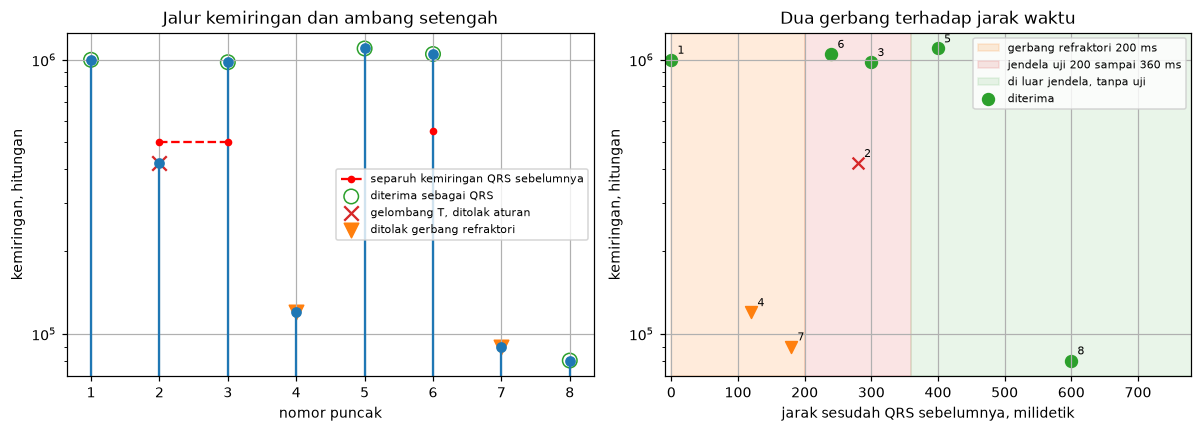

deret buatan 8 puncak: diterima 5, ditolak uji kemiringan 1, ditolak gerbang refraktori 2
jarak puncak ke QRS lalu: 0, 280, 300, 120, 400, 240, 180, 600 milidetik


In [7]:
# Tujuan: menggambar jalur kemiringan deret puncak buatan beserta ambang setengah kemiringan QRS
# sebelumnya, dan menggambar keputusan kedua gerbang terhadap jarak sesudah QRS.
# Cell ini menghasilkan satu gambar dengan dua panel.

# ==== CELL 13: gambar jalur kemiringan deret puncak buatan ====
baris_gambar = jalankan_deret(deret_buatan, aturan_t=True)
posisi_uji = np.array([b["pos"] for b in baris_gambar], dtype=float)
kem_uji2 = np.array([b["kem"] for b in baris_gambar], dtype=float)
putusan2 = [b["putusan"] for b in baris_gambar]
ambang2 = np.array([np.nan if b["kem_lalu"] is None else 0.5 * b["kem_lalu"] for b in baris_gambar], dtype=float)
jarak2 = np.array([0.0 if b["jarak"] is None else float(b["jarak"]) for b in baris_gambar])
diterima2 = np.array([v.startswith("QRS") for v in putusan2])
ditolak_t = np.array([v.startswith("gelombang") for v in putusan2])
ditolak_r = np.array([v.startswith("ditolak") for v in putusan2])

fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.0))
ax[0].stem(np.arange(1, 9), kem_uji2, basefmt=" ", linefmt="C0-", markerfmt="C0o")
ax[0].plot(np.arange(1, 9), ambang2, "r--o", ms=4, label="separuh kemiringan QRS sebelumnya")
ax[0].scatter(np.nonzero(diterima2)[0] + 1, kem_uji2[diterima2], s=90, facecolors="none",
              edgecolors="C2", label="diterima sebagai QRS")
ax[0].scatter(np.nonzero(ditolak_t)[0] + 1, kem_uji2[ditolak_t], s=90, marker="x", color="C3",
              label="gelombang T, ditolak aturan")
ax[0].scatter(np.nonzero(ditolak_r)[0] + 1, kem_uji2[ditolak_r], s=90, marker="v", color="C1",
              label="ditolak gerbang refraktori")
ax[0].set_yscale("log")
ax[0].set_xlabel("nomor puncak")
ax[0].set_ylabel("kemiringan, hitungan")
ax[0].set_title("Jalur kemiringan dan ambang setengah")
ax[0].legend(fontsize=7)

ax[1].axvspan(0, 200, color="C1", alpha=0.15, label="gerbang refraktori 200 ms")
ax[1].axvspan(200, 360, color="C3", alpha=0.12, label="jendela uji 200 sampai 360 ms")
ax[1].axvspan(360, 800, color="C2", alpha=0.10, label="di luar jendela, tanpa uji")
ax[1].scatter(jarak2[diterima2], kem_uji2[diterima2], s=60, color="C2", label="diterima")
ax[1].scatter(jarak2[ditolak_t], kem_uji2[ditolak_t], s=60, marker="x", color="C3")
ax[1].scatter(jarak2[ditolak_r], kem_uji2[ditolak_r], s=60, marker="v", color="C1")
for i, (x, y) in enumerate(zip(jarak2, kem_uji2)):
    ax[1].annotate(str(i + 1), (x, y), textcoords="offset points", xytext=(4, 4), fontsize=7)
ax[1].set_yscale("log")
ax[1].set_xlim(-10, 780)
ax[1].set_xlabel("jarak sesudah QRS sebelumnya, milidetik")
ax[1].set_ylabel("kemiringan, hitungan")
ax[1].set_title("Dua gerbang terhadap jarak waktu")
ax[1].legend(fontsize=7)
fig.tight_layout()
plt.show()
print("deret buatan %d puncak: diterima %d, ditolak uji kemiringan %d, ditolak gerbang refraktori %d" % (
    posisi_uji.size, int(diterima2.sum()), int(ditolak_t.sum()), int(ditolak_r.sum())))
print("jarak puncak ke QRS lalu: %s milidetik" % ", ".join("%.0f" % v for v in jarak2))

## 7. Kasus sebelum dan sesudah pada EKG buatan yang gelombang T-nya menonjol

EKG buatan di bawah ini dipakai sebagai kasus sebelum dan sesudah yang diminta. Denyutnya tetap:
satu kompleks QRS sempit 1,5 milivolt dengan setengah lebar 16 milidetik, satu gelombang P kecil,
dan satu gelombang T lebar dengan setengah lebar 60 milidetik yang puncaknya 280 milidetik sesudah
QRS. Jarak itu sengaja dipilih supaya gelombang T jatuh di dalam jendela 360 milidetik dan di luar
gerbang refraktori 200 milidetik, jadi gelombang T itu memang diperiksa aturan. Denyut berulang
setiap 700 milidetik selama 120 detik, sehingga ada 170 denyut.

Amplitudo gelombang T disapu dari 0,20 sampai 1,30 milivolt. Penilaian denyut dipisahkan dari gerak
potong pertama dalam notebook versi sebelumnya: seluruh denyut dinilai pada jendela uji yang sama
untuk kedua keadaan aturan, yaitu mulai 15 detik sampai ujung rekaman, sehingga jumlah denyut
sebelum dan sesudah dapat dibandingkan langsung. Kolom `T palsu sebelum` adalah jumlah gelombang T
yang salah diterima sebagai denyut ketika aturan dimatikan, kolom `T palsu sesudah` adalah jumlah
yang masih lolos ketika aturan dinyalakan, dan kedua kolom QRS hilang adalah jumlah QRS buatan yang
tidak tertangkap oleh detektor pada jendela uji itu.

**Batas keberlakuan resmi aturan ini adalah 0,90 milivolt amplitudo gelombang T.** Batas itu
ditulis di sini sebagai batas resmi, bukan sebagai catatan kaki, dan dikunci sebagai keputusan
P5-5. Di bawah batas itu aturan terbukti menolak seluruh gelombang T palsu tanpa kehilangan satu
QRS sah pun; tepat di batas itu dan di atasnya aturan mulai kehilangan daya, dan pada amplitudo
1,30 milivolt aturan justru menolak QRS yang sah. Setiap pemakaian aturan ini di luar rekaman uji
karena itu harus memeriksa lebih dulu bahwa amplitudo gelombang T tidak melewati batas 0,90
milivolt; di atas batas itu aturan hanya boleh dipakai bersama pemeriksaan amplitudo tambahan.

Tabel di sel berikutnya menandai tiap baris sapuan dengan kolom `di dalam batas 0,90 mV`, sehingga
batas resmi itu dapat dibaca langsung pada baris mana pun. Dua tabel pertama adalah sapuan
amplitudo dan tukar menukar deteksi palsu lawan QRS yang hilang, dan rincian tiga amplitudo
dicetak setelahnya.

In [8]:
# Tujuan: membangun EKG buatan bergelombang T menonjol, menjalankan rantai bilangan bulat terkunci
# di atasnya, dan mengukur kasus sebelum dan sesudah aturan gelombang T dengan batas keberlakuan
# resmi 0,90 milivolt dari P5-5, termasuk tukar menukar deteksi palsu dan QRS yang hilang.
# Cell ini mencetak tabel sapuan amplitudo, tabel tukar menukar, dan rincian tiga amplitudo.

# ==== CELL 15: sapuan amplitudo gelombang T pada EKG buatan ====
DURASI_S = 120.0
RR_MS = 700.0
T_MS = 280.0
AQ = 1.5
HQ_MS = 16.0
HT_MS = 60.0
TOL_SAMPEL = 12
JENDELA_UJI_S = 15.0
AMPUTAN = (0.20, 0.30, 0.40, 0.50, 0.70, 0.90, 1.10, 1.30)
RANTAI_BUATAN = {}
SAPUAN = {}


def pulsa_segitiga(amp, hw_s):
    hw = int(round(hw_s * FS))
    idx = np.arange(-hw, hw + 1)
    return amp * (1.0 - np.abs(idx) / hw), hw


def tambah(x, pos, y):
    a = max(0, int(pos))
    b = min(x.size, a + y.size)
    x[a:b] += y[:b - a]


def grid_buatan():
    period = int(round(RR_MS / 1000.0 * FS))
    return np.array([t for t in range(int(0.6 * FS), int(DURASI_S * FS) - period, period)], dtype=np.int64), period


def ekg_buatan(amp_t, hanya_qrs=False, hanya_t=False, bising=0.010, seed=11):
    n = int(DURASI_S * FS)
    x = np.zeros(n)
    mulai, _ = grid_buatan()
    hw_t = int(round(HT_MS / 1000.0 * FS))
    idx_t = np.arange(-hw_t, hw_t + 1)
    kos_t = 0.5 * amp_t * (1.0 + np.cos(np.pi * idx_t / hw_t))
    hw_p = int(round(30.0 / 1000.0 * FS))
    idx_p = np.arange(-hw_p, hw_p + 1)
    kos_p = 0.05 * (1.0 + np.cos(np.pi * idx_p / hw_p))
    qrs, hw_q = pulsa_segitiga(AQ, HQ_MS / 1000.0)
    for t in mulai:
        if not hanya_t:
            tambah(x, t, qrs)
        if not hanya_qrs:
            tambah(x, t + int(T_MS / 1000.0 * FS), kos_t)
        if not (hanya_qrs or hanya_t):
            tambah(x, t - int(160.0 / 1000.0 * FS), kos_p)
    rng = np.random.default_rng(seed)
    return x + bising * rng.standard_normal(n), hw_q


def rantai_buatan(x):
    kata = kuantisasi(x)
    a1, a2, a3 = rantai_tapis(kata)
    _, s = selubung_bergantian(a3)
    return a2, a3, s, puncak_radius(s, 27)


mulai_buatan, _ = grid_buatan()
hw_q = int(round(HQ_MS / 1000.0 * FS))
qrs_ref = mulai_buatan + hw_q
t_ref = mulai_buatan + int(round(T_MS / 1000.0 * FS))
_, _, sel_q, pk_q = rantai_buatan(ekg_buatan(0.70, hanya_qrs=True)[0])
tunda_q = float(np.median([p - qrs_ref[np.argmin(np.abs(qrs_ref - p))] for p in pk_q]))
_, _, sel_t, pk_t = rantai_buatan(ekg_buatan(0.70, hanya_t=True)[0])
tunda_t = float(np.median([p - t_ref[np.argmin(np.abs(t_ref - p))] for p in pk_t]))
qrs_harap = qrs_ref + tunda_q
t_harap = t_ref + tunda_t
mulai_uji = int(round(JENDELA_UJI_S * FS))
print("jaringan buatan: %d denyut, RR %d ms, gelombang T pada %d ms sesudah QRS" % (
    mulai_buatan.size, int(RR_MS), int(T_MS)))
print("tunda puncak selubung: QRS %.0f sampel, gelombang T %.0f sampel" % (tunda_q, tunda_t))
print("jendela uji nilai: mulai %.1f detik, acuan QRS %d denyut dan acuan gelombang T %d denyut" % (
    JENDELA_UJI_S, int((qrs_harap >= mulai_uji).sum()), int((t_harap >= mulai_uji).sum())))
print("batas keberlakuan resmi P5-5: amplitudo gelombang T %.2f milivolt" % BATAS_KEBERLAKUAN_MV)
print()


def rantai_amp(amp):
    """Rantai bilangan bulat pada EKG buatan amplitudo tertentu, dihitung sekali per amplitudo."""
    if amp not in RANTAI_BUATAN:
        RANTAI_BUATAN[amp] = rantai_buatan(ekg_buatan(amp)[0])
    return RANTAI_BUATAN[amp]


def nilai_denyut(beats, qh, th, mulai):
    """Nilai satu deret denyut: QRS tertangkap, QRS hilang, deteksi palsu gelombang T dan lain."""
    b = np.array([int(x) for x in beats if int(x) >= mulai], dtype=np.int64)
    rq = qh[qh >= mulai]
    rt = th[th >= mulai]
    tertangkap = 0
    for r in rq:
        if b.size and int(np.min(np.abs(b - r))) <= TOL_SAMPEL:
            tertangkap += 1
    jenis = []
    for x in b:
        dq = int(np.min(np.abs(rq - x))) if rq.size else 10 ** 9
        dt = int(np.min(np.abs(rt - x))) if rt.size else 10 ** 9
        if min(dq, dt) > TOL_SAMPEL:
            jenis.append("lain")
        else:
            jenis.append("qrs" if dq <= dt else "t")
    return dict(acuan=int(rq.size), tertangkap=int(tertangkap), hilang=int(rq.size - tertangkap),
                benar=int(jenis.count("qrs")), palsu=int(jenis.count("t") + jenis.count("lain")),
                palsu_t=int(jenis.count("t")), denyut=int(b.size))


print("| amplitudo T (mV) | di dalam batas 0,90 mV | kemiringan T / QRS | T palsu sebelum | QRS hilang sebelum | T palsu sesudah | QRS hilang sesudah | denyut sebelum | denyut sesudah |")
print("|---|---|---|---|---|---|---|---|---|")
for amp in AMPUTAN:
    hpb, db, selb, pkb = rantai_amp(amp)
    kolom = {}
    for nama, aturan in (("mati", False), ("hidup", True)):
        h = jalankan(selb, pkb, hpb, mode_half="tidak", aturan_t=aturan)
        kolom[nama] = nilai_denyut(h["qrs"], qrs_harap, t_harap, mulai_uji)
        kolom[nama].update(diperiksa=h["diperiksa"], ditolak=h["ditolak"],
                           diterima_pita=h["diterima_pita"], langkah=h["langkah"], semai=h["semai"])
    rasio = float(np.median([kemiringan(db, int(t), 18) for t in t_ref if t + 18 < selb.size])) / \
        float(np.median([kemiringan(db, int(q), 18) for q in qrs_ref if q + 18 < selb.size]))
    SAPUAN[amp] = (kolom, rasio)
    print("| %.2f | %s | %.4f | %d | %d | %d | %d | %d | %d |" % (
        amp, "ya" if amp <= BATAS_KEBERLAKUAN_MV else "tidak", rasio, kolom["mati"]["palsu"],
        kolom["mati"]["hilang"], kolom["hidup"]["palsu"], kolom["hidup"]["hilang"],
        kolom["mati"]["denyut"], kolom["hidup"]["denyut"]))
print()
print("tukar menukar deteksi palsu dan QRS yang hilang, amplitudo di dalam batas keberlakuan:")
print("| amplitudo T (mV) | deteksi palsu turun | QRS sah hilang bertambah | QRS tertangkap sebelum | QRS tertangkap sesudah | acuan QRS |")
print("|---|---|---|---|---|---|")
for amp in AMPUTAN:
    kolom, rasio = SAPUAN[amp]
    print("| %.2f | %d | %d | %d | %d | %d |" % (
        amp, kolom["mati"]["palsu"] - kolom["hidup"]["palsu"],
        kolom["hidup"]["hilang"] - kolom["mati"]["hilang"], kolom["mati"]["tertangkap"],
        kolom["hidup"]["tertangkap"], kolom["mati"]["acuan"]))
print()
for amp in (0.30, 0.70, 0.90):
    kolom, rasio = SAPUAN[amp]
    print("amplitudo T %.2f mV, rasio kemiringan T terhadap QRS %.4f" % (amp, rasio))
    for nama in ("mati", "hidup"):
        k = kolom[nama]
        print("  aturan %-5s : denyut %3d = QRS %3d + gelombang T %3d + lain %3d, QRS hilang %d dari %d" % (
            nama, k["denyut"], k["benar"], k["palsu_t"], k["denyut"] - k["benar"] - k["palsu_t"],
            k["hilang"], k["acuan"]))
    print("  uji kemiringan aturan hidup: diperiksa %d, ditolak %d, diterima %d, penyemaian ulang %d" % (
        kolom["hidup"]["diperiksa"], kolom["hidup"]["ditolak"], kolom["hidup"]["diterima_pita"],
        kolom["hidup"]["semai"]))
HASIL["buatan T salah diterima"] = int(SAPUAN[0.70][0]["mati"]["palsu_t"])
HASIL["buatan T ditolak aturan"] = int(SAPUAN[0.70][0]["hidup"]["ditolak"])
HASIL["buatan T lolos sesudah"] = int(SAPUAN[0.70][0]["hidup"]["palsu_t"])
HASIL["buatan denyut sebelum"] = int(SAPUAN[0.70][0]["mati"]["denyut"])
HASIL["buatan denyut sesudah"] = int(SAPUAN[0.70][0]["hidup"]["denyut"])
HASIL["buatan qrs sebelum"] = int(SAPUAN[0.70][0]["mati"]["benar"])
HASIL["buatan qrs sesudah"] = int(SAPUAN[0.70][0]["hidup"]["benar"])
HASIL["buatan palsu turun"] = int(SAPUAN[0.70][0]["mati"]["palsu"] - SAPUAN[0.70][0]["hidup"]["palsu"])
HASIL["buatan hilang bertambah"] = int(SAPUAN[0.70][0]["hidup"]["hilang"] - SAPUAN[0.70][0]["mati"]["hilang"])
HASIL["buatan QRS hilang sebelum"] = int(SAPUAN[0.70][0]["mati"]["hilang"])
HASIL["buatan QRS hilang sesudah"] = int(SAPUAN[0.70][0]["hidup"]["hilang"])
HASIL["buatan acuan QRS"] = int(SAPUAN[0.70][0]["mati"]["acuan"])

jaringan buatan: 170 denyut, RR 700 ms, gelombang T pada 280 ms sesudah QRS
tunda puncak selubung: QRS 37 sampel, gelombang T 56 sampel
jendela uji nilai: mulai 15.0 detik, acuan QRS 149 denyut dan acuan gelombang T 150 denyut
batas keberlakuan resmi P5-5: amplitudo gelombang T 0.90 milivolt

| amplitudo T (mV) | di dalam batas 0,90 mV | kemiringan T / QRS | T palsu sebelum | QRS hilang sebelum | T palsu sesudah | QRS hilang sesudah | denyut sebelum | denyut sesudah |
|---|---|---|---|---|---|---|---|---|
| 0.20 | ya | 0.0137 | 0 | 0 | 0 | 0 | 149 | 149 |


| 0.30 | ya | 0.0147 | 0 | 0 | 0 | 0 | 149 | 149 |
| 0.40 | ya | 0.0153 | 0 | 0 | 0 | 0 | 149 | 149 |


| 0.50 | ya | 0.0164 | 150 | 0 | 0 | 0 | 299 | 149 |
| 0.70 | ya | 0.0200 | 150 | 0 | 0 | 0 | 299 | 149 |


| 0.90 | ya | 0.0235 | 150 | 0 | 0 | 0 | 299 | 149 |
| 1.10 | tidak | 0.0275 | 150 | 0 | 28 | 3 | 299 | 174 |


| 1.30 | tidak | 0.0315 | 150 | 0 | 148 | 145 | 299 | 152 |

tukar menukar deteksi palsu dan QRS yang hilang, amplitudo di dalam batas keberlakuan:
| amplitudo T (mV) | deteksi palsu turun | QRS sah hilang bertambah | QRS tertangkap sebelum | QRS tertangkap sesudah | acuan QRS |
|---|---|---|---|---|---|
| 0.20 | 0 | 0 | 149 | 149 | 149 |
| 0.30 | 0 | 0 | 149 | 149 | 149 |
| 0.40 | 0 | 0 | 149 | 149 | 149 |
| 0.50 | 150 | 0 | 149 | 149 | 149 |
| 0.70 | 150 | 0 | 149 | 149 | 149 |
| 0.90 | 150 | 0 | 149 | 149 | 149 |
| 1.10 | 122 | 3 | 149 | 146 | 149 |
| 1.30 | 2 | 145 | 149 | 4 | 149 |

amplitudo T 0.30 mV, rasio kemiringan T terhadap QRS 0.0147
  aturan mati  : denyut 149 = QRS 149 + gelombang T   0 + lain   0, QRS hilang 0 dari 149
  aturan hidup : denyut 149 = QRS 149 + gelombang T   0 + lain   0, QRS hilang 0 dari 149
  uji kemiringan aturan hidup: diperiksa 2, ditolak 2, diterima 0, penyemaian ulang 0
amplitudo T 0.70 mV, rasio kemiringan T terhadap QRS 0.0200
  aturan mati  : de

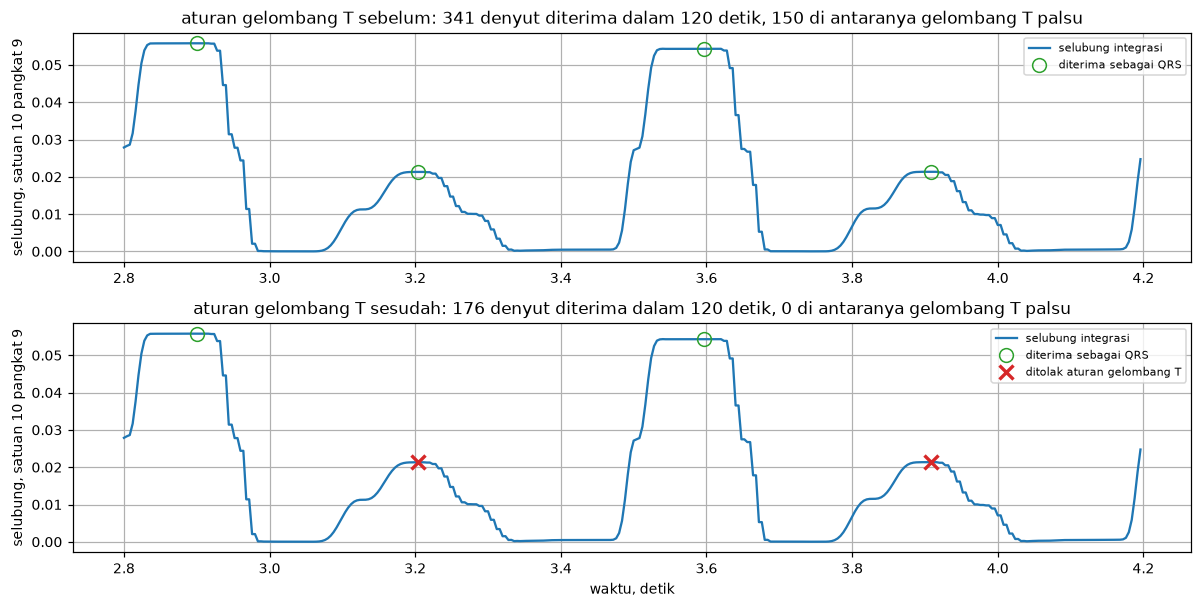

aturan sebelum: 341 denyut diterima, 0 puncak ditolak aturan, 0 diperiksa uji kemiringan
aturan sesudah: 176 denyut diterima, 6 puncak ditolak aturan, 9 diperiksa uji kemiringan
potongan yang digambar 2,8 sampai 4,2 detik, 350 sampel selubung


In [9]:
# Tujuan: menggambar panel sebelum dan sesudah pada EKG buatan yang gelombang T-nya menonjol,
# yaitu selubung integrasi 1,4 detik dengan tanda denyut yang diterima dan puncak yang ditolak.
# Cell ini menghasilkan satu gambar dengan dua panel.

# ==== CELL 16: gambar panel sebelum dan sesudah pada EKG buatan ====
hpb, db, selb, pkb = rantai_amp(0.70)
a0 = int(2.8 * FS)
b0 = int(4.2 * FS)
hasil_panel = {}
for nama, aturan in (("sebelum", False), ("sesudah", True)):
    h = jalankan(selb, pkb, hpb, mode_half="tidak", aturan_t=aturan)
    hasil_panel[nama] = (h, np.array(h["qrs"], dtype=np.int64),
                         np.array([x[0] for x in h["tolakan"]], dtype=np.int64))

fig, ax = plt.subplots(2, 1, figsize=(11.0, 5.6))
for k, nama in enumerate(("sebelum", "sesudah")):
    h, beats, tolak = hasil_panel[nama]
    ax[k].plot(np.arange(a0, b0) / FS, selb[a0:b0] / 1e9, color="C0", label="selubung integrasi")
    bb = beats[(beats >= a0) & (beats < b0)]
    ax[k].plot(bb / FS, selb[bb] / 1e9, "o", color="C2", ms=9, mfc="none",
               label="diterima sebagai QRS")
    tt = tolak[(tolak >= a0) & (tolak < b0)]
    if tt.size:
        ax[k].plot(tt / FS, selb[tt] / 1e9, "x", color="C3", ms=9, mew=2.2,
                   label="ditolak aturan gelombang T")
    ax[k].set_title("aturan gelombang T %s: %d denyut diterima dalam 120 detik, %d di antaranya gelombang T palsu" % (
        nama, len(h["qrs"]), int(SAPUAN[0.70][0][("mati" if k == 0 else "hidup")]["palsu_t"])))
    ax[k].set_ylabel("selubung, satuan 10 pangkat 9")
    ax[k].legend(fontsize=7, loc="upper right")
ax[1].set_xlabel("waktu, detik")
fig.tight_layout()
plt.show()
for nama in ("sebelum", "sesudah"):
    h, beats, tolak = hasil_panel[nama]
    print("aturan %-7s: %d denyut diterima, %d puncak ditolak aturan, %d diperiksa uji kemiringan" % (
        nama, len(h["qrs"]), len(tolak), h["diperiksa"]))
print("potongan yang digambar 2,8 sampai 4,2 detik, %d sampel selubung" % (b0 - a0))

## 8. Dua pembacaan kemiringan pada sinyal buatan yang sama

Bagian ini menguji keputusan **P5-2** secara langsung. Dua pembacaan kemiringan dijalankan pada
sinyal buatan yang sama, pada amplitudo gelombang T yang sama, dan pada aturan gelombang T yang
sama: bacaan pertama dari keluaran tahap turunan lima titik yang menjadi bawaan, bacaan kedua dari
beda pertama EKG terfilter yang tinggal menjadi pembanding. Yang dicetak adalah jumlah gelombang T
yang lolos pada masing-masing cara, jumlah QRS yang hilang, dan jarak kemiringan gelombang T
terhadap ambang setengah pada masing-masing cara.

Jarak terhadap ambang itu diukur sebagai median kemiringan gelombang T dibagi median kemiringan QRS
pada besaran yang sama, karena aturan halaman 234 membandingkan kemiringan gelombang T terhadap
kemiringan QRS sebelumnya. Bacaan yang menempatkan gelombang T lebih jauh di bawah ambang setengah
adalah bacaan yang lebih tahan terhadap gelombang T yang membesar, dan itulah alasan terukur di
balik pilihan P5-2.

In [10]:
# Tujuan: membandingkan dua pembacaan kemiringan pada sinyal buatan yang sama, keluaran turunan lima
# titik sebagai bawaan P5-2 lawan beda EKG terfilter sebagai pembanding singkat, dengan angka
# gelombang T yang lolos pada masing-masing cara dan jarak kemiringannya terhadap ambang setengah.
# Cell ini mencetak tabel gelombang T yang lolos dan tabel rasio kemiringan terhadap QRS.

# ==== CELL 18: dua pembacaan kemiringan pada sinyal buatan yang sama ====
if not RANTAI_BUATAN:
    for amp in AMPUTAN:
        rantai_amp(amp)
print("dua pembacaan kemiringan pada sinyal buatan yang sama, P5-2")
print("besaran bawaan keluaran turunan lima titik, pembanding singkat beda EKG terfilter")
print("| amplitudo T (mV) | T lolos turunan sebelum | T lolos turunan sesudah | T lolos beda sebelum | T lolos beda sesudah | QRS hilang turunan sesudah | QRS hilang beda sesudah |")
print("|---|---|---|---|---|---|---|")
BACAAN = {}
for amp in AMPUTAN:
    hpb, db, selb, pkb = rantai_amp(amp)
    baris_amp = {}
    for nama, besaran in (("turunan", "turunan"), ("beda", "beda")):
        for keadaan, aturan in (("mati", False), ("hidup", True)):
            h = jalankan(selb, pkb, hpb, besaran=besaran, mode_half="tidak", aturan_t=aturan)
            baris_amp[(nama, keadaan)] = nilai_denyut(h["qrs"], qrs_harap, t_harap, mulai_uji)
    BACAAN[amp] = baris_amp
    print("| %.2f | %d | %d | %d | %d | %d | %d |" % (
        amp, baris_amp[("turunan", "mati")]["palsu_t"], baris_amp[("turunan", "hidup")]["palsu_t"],
        baris_amp[("beda", "mati")]["palsu_t"], baris_amp[("beda", "hidup")]["palsu_t"],
        baris_amp[("turunan", "hidup")]["hilang"], baris_amp[("beda", "hidup")]["hilang"]))
print()
print("sisi yang membedakan dua cara itu bukan jumlah gelombang T yang lolos, melainkan jarak kemiringan")
print("gelombang T terhadap ambang setengah. Jarak itu diukur sebagai median kemiringan gelombang T dibagi")
print("median kemiringan QRS pada besaran yang sama, jendela kemiringan %d sampel." % LEBAR_JENDELA_KEMIRINGAN)
print("| amplitudo T (mV) | rasio T terhadap QRS cara turunan | rasio T terhadap QRS cara beda | nisbah beda terhadap turunan |")
print("|---|---|---|---|")
NISBAH = {}
for amp in AMPUTAN:
    hpb, db, selb, pkb = rantai_amp(amp)
    beda_db = beda_terfilter(hpb)
    hasil_rasio = {}
    for nama, der in (("turunan", db), ("beda", beda_db)):
        atas = float(np.median([kemiringan(der, int(t), SETENGAH_JENDELA) for t in t_ref
                                if t + SETENGAH_JENDELA < der.size]))
        bawah = float(np.median([kemiringan(der, int(q), SETENGAH_JENDELA) for q in qrs_ref
                                 if q + SETENGAH_JENDELA < der.size]))
        hasil_rasio[nama] = atas / bawah
    NISBAH[amp] = (hasil_rasio["turunan"], hasil_rasio["beda"], hasil_rasio["beda"] / hasil_rasio["turunan"])
    print("| %.2f | %.5f | %.5f | %.4f |" % (amp, NISBAH[amp][0], NISBAH[amp][1], NISBAH[amp][2]))
print("nisbah terbesar %.4f dan terkecil %.4f, jadi pada sinyal buatan ini cara beda EKG terfilter menempatkan" % (
    max(v[2] for v in NISBAH.values()), min(v[2] for v in NISBAH.values())))
print("gelombang T lebih dekat ke ambang setengah daripada cara keluaran turunan lima titik.")
print()
for amp in (0.50, 0.70, 0.90):
    b = BACAAN[amp]
    print("amplitudo T %.2f mV" % amp)
    for nama in ("turunan", "beda"):
        print("  cara %-8s: gelombang T lolos sebelum aturan %d, sesudah aturan %d, QRS hilang sesudah %d" % (
            nama, b[(nama, "mati")]["palsu_t"], b[(nama, "hidup")]["palsu_t"], b[(nama, "hidup")]["hilang"]))
    print("  rasio T terhadap QRS: cara turunan %.5f, cara beda %.5f" % (NISBAH[amp][0], NISBAH[amp][1]))
kiri = sum(BACAAN[a][("turunan", "hidup")]["palsu_t"] for a in AMPUTAN)
kanan = sum(BACAAN[a][("beda", "hidup")]["palsu_t"] for a in AMPUTAN)
print("jumlah gelombang T yang masih lolos sesudah aturan, dijumlahkan pada %d amplitudo:" % len(AMPUTAN))
print("  cara keluaran turunan lima titik : %d" % kiri)
print("  cara beda EKG terfilter          : %d" % kanan)
print("jumlah itu sama pada kedua cara, sehingga pilihan P5-2 bersandar pada kalimat halaman 232 soal tahap")
print("turunan sebagai pembawa informasi kemiringan QRS dan pada jarak terhadap ambang yang lebih lebar itu.")
HASIL["beda cara T lolos turunan"] = int(kiri)
HASIL["beda cara T lolos beda"] = int(kanan)
HASIL["beda cara T lolos 0,70 turunan"] = int(BACAAN[0.70][("turunan", "hidup")]["palsu_t"])
HASIL["beda cara T lolos 0,70 beda"] = int(BACAAN[0.70][("beda", "hidup")]["palsu_t"])
HASIL["nisbah rasio T terbesar"] = float(max(v[2] for v in NISBAH.values()))
HASIL["rasio T turunan 0,70"] = float(NISBAH[0.70][0])
HASIL["rasio T beda 0,70"] = float(NISBAH[0.70][1])

dua pembacaan kemiringan pada sinyal buatan yang sama, P5-2
besaran bawaan keluaran turunan lima titik, pembanding singkat beda EKG terfilter
| amplitudo T (mV) | T lolos turunan sebelum | T lolos turunan sesudah | T lolos beda sebelum | T lolos beda sesudah | QRS hilang turunan sesudah | QRS hilang beda sesudah |
|---|---|---|---|---|---|---|
| 0.20 | 0 | 0 | 0 | 0 | 0 | 0 |
| 0.30 | 0 | 0 | 0 | 0 | 0 | 0 |
| 0.40 | 0 | 0 | 0 | 0 | 0 | 0 |
| 0.50 | 150 | 0 | 150 | 0 | 0 | 0 |
| 0.70 | 150 | 0 | 150 | 0 | 0 | 0 |
| 0.90 | 150 | 0 | 150 | 0 | 0 | 0 |
| 1.10 | 150 | 28 | 150 | 28 | 3 | 3 |


| 1.30 | 150 | 148 | 150 | 148 | 145 | 145 |

sisi yang membedakan dua cara itu bukan jumlah gelombang T yang lolos, melainkan jarak kemiringan
gelombang T terhadap ambang setengah. Jarak itu diukur sebagai median kemiringan gelombang T dibagi
median kemiringan QRS pada besaran yang sama, jendela kemiringan 37 sampel.
| amplitudo T (mV) | rasio T terhadap QRS cara turunan | rasio T terhadap QRS cara beda | nisbah beda terhadap turunan |
|---|---|---|---|
| 0.20 | 0.01370 | 0.01921 | 1.4028 |
| 0.30 | 0.01470 | 0.01987 | 1.3523 |
| 0.40 | 0.01525 | 0.02031 | 1.3313 |
| 0.50 | 0.01640 | 0.02103 | 1.2821 |
| 0.70 | 0.02003 | 0.02337 | 1.1670 |
| 0.90 | 0.02350 | 0.02586 | 1.1004 |
| 1.10 | 0.02746 | 0.02883 | 1.0496 |
| 1.30 | 0.03150 | 0.03193 | 1.0136 |
nisbah terbesar 1.4028 dan terkecil 1.0136, jadi pada sinyal buatan ini cara beda EKG terfilter menempatkan
gelombang T lebih dekat ke ambang setengah daripada cara keluaran turunan lima titik.

amplitudo T 0.50 mV
  cara turunan : gelom

## 9. Pengukuran pada rekaman AFDB 04015

Rekaman uji terkunci adalah AFDB `04015`, 450.000 sampel pertama, 250 Hz, 1800,0 detik. Rantai yang
dijalankan adalah rantai bilangan bulat terkunci yang sama dengan fase 3 dan fase 4. Angka acuan
yang dikunci di fase 4 adalah 2.605 denyut sebelum aturan dengan pemotongan separuh ambang
dimatikan dan 2.625 denyut dengan pemotongan hidup; angka itu berlaku untuk keadaan aturan
penyemaian ulang dimatikan. Dengan aturan penyemaian ulang hidup, deret sebelum aturan terukur
2.603 denyut, karena penyemaian ulang ikut mengubah jalur ambang sejak keadaan pembanding. Sel
berikutnya mencetak kedua angka itu berdampingan supaya selisihnya tidak tersembunyi.

Lima angka yang diukur di sini. Pertama, jumlah denyut sebelum dan sesudah aturan diaktifkan.
Kedua, jumlah kandidat di dalam jendela 360 milidetik dan berapa yang ditolak. Ketiga, sebaran
rasio kemiringan kandidat terhadap kemiringan QRS sebelumnya. Keempat, dan ini risiko yang harus
dilaporkan terbuka, berapa banyak QRS sah di dalam pita 200 sampai 360 milidetik yang rasionya
kurang dari setengah, karena puncak semacam itu ikut tertolak bersama gelombang T palsu. Kelima,
berapa kali aturan penyemaian ulang antrean delapan interval bekerja pada tiap keadaan.

Satu catatan tentang jalur ambang kedua. Pada keadaan pemotongan separuh hidup, kolam kandidat
jalur ambang kedua berjumlah 272 sebelum aturan dan 277 sesudah aturan, dan karena puncak yang
ditolak aturan tidak masuk ke kolam itu sebagai kandidat, jumlah kolam ikut bergerak.

Catatan kedua, dan ini ditemukan saat menghitung ulang, menyangkut deret interval RR itu sendiri.
Rantai ambang adaptif dari fase 2 dan fase 3 meninggalkan beberapa interval di luar topeng 250
sampai 2000 milidetik pada rekaman ini, dengan jarak terbesar 51064 milidetik, yaitu sekitar 51
detik tanpa denyut yang diterima. Topeng itu memang ada untuk menolak interval semacam itu, jadi
perhitungan rata-rata RR tidak terpengaruh, tetapi jarak tanpa denyut itu adalah cacat rantai
ambang, bukan cacat aturan gelombang T, dan cacat itu harus dibawa ke fase berikutnya. Sel
berikutnya mencetak jumlah interval di luar topeng itu apa adanya.

Catatan ketiga, dan ini yang berubah dari versi sebelumnya, menyangkut penanda irama teratur
persamaan (29). Pada versi sebelumnya, penolakan beberapa puncak di awal rekaman membuat penanda
itu berhenti menyala pada seluruh rekaman, dari 1.129 penyalaan menjadi nol, karena antrean
interval lolos tidak pernah terisi kembali sementara rata-rata kedua sudah menyimpang. Aturan
penyemaian ulang menutup lubang itu: bila tidak ada interval RR yang lolos pita 0,92 sampai 1,16
kali rata-rata kedua selama 8 denyut berturut-turut, antrean delapan interval diisi ulang memakai
median 32 interval RR terakhir, lalu rata-rata kedua dihitung ulang dari antrean itu, dan
penyemaian ulang dibatasi paling banyak sekali per 8 denyut. Pada rekaman ini penanda menyala 1.202
kali ketika aturan hidup, sedangkan tanpa penyemaian ulang penanda itu menyala nol kali. Sel
pelacakan di bawah mencetak langkah pertama tahap RR pada keempat keadaan, yaitu dua keadaan aturan
kali dua keadaan penyemaian ulang, supaya mekanisme itu dapat diperiksa sendiri.

In [11]:
# Tujuan: mengukur aturan gelombang T pada rekaman AFDB 04015, yaitu jumlah denyut sebelum dan
# sesudah, kolam kandidat jalur ambang kedua, jumlah kandidat di dalam jendela 360 milidetik,
# jumlah yang ditolak, sebaran rasio kemiringannya, jumlah QRS sah yang berisiko ikut tertolak,
# dan jumlah penyemaian ulang antrean delapan interval.
# Cell ini mencetak tabel dua keadaan pemotongan separuh, ringkasan pita, dan tabel tolakan.

# ==== CELL 20: pengukuran aturan gelombang T pada rekaman 04015 ====
UKUR = {}
for mh in ("tidak", "paksa"):
    off = jalankan(sel, puncak, y2, mode_half=mh, aturan_t=False)
    on = jalankan(sel, puncak, y2, mode_half=mh)
    UKUR[mh] = dict(off=off, on=on)
    print("pemotongan separuh %s" % mh)
    print("  denyut sebelum aturan %d, sesudah aturan %d, selisih %d" % (
        len(off["qrs"]), len(on["qrs"]), len(off["qrs"]) - len(on["qrs"])))
    print("  kolam kandidat jalur ambang kedua: sebelum %d, sesudah %d" % (off["calon_kedua"], on["calon_kedua"]))
    print("  aktivasi pencarian mundur       : sebelum %d, sesudah %d" % (off["cari_mundur"], on["cari_mundur"]))
    print("  penanda irama teratur menyala   : sebelum %d, sesudah %d dari %d langkah" % (
        off["penanda"], on["penanda"], off["langkah"]))
    print("  penyemaian ulang antrean RR     : sebelum %d, sesudah %d" % (off["semai"], on["semai"]))
    print("  kandidat diperiksa uji kemiringan %d, ditolak %d, diterima %d" % (
        on["diperiksa"], on["ditolak"], on["diterima_pita"]))
    print("  rasio kemiringan kandidat terhadap QRS sebelumnya di dalam jendela 360 ms:")
    if on["rasio_pita"].size:
        q = np.percentile(on["rasio_pita"], [0, 10, 50, 90, 100])
        print("    n %d, minimum %.4f, persentil 10 %.4f, median %.4f, persentil 90 %.4f, maksimum %.4f" % (
            on["rasio_pita"].size, q[0], q[1], q[2], q[3], q[4]))
    print("  QRS sah di dalam pita yang rasionya kurang dari setengah: %d dari %d (%.4f)" % (
        off["berisiko"], off["rasio_qrs"].size,
        off["berisiko"] / off["rasio_qrs"].size if off["rasio_qrs"].size else 0.0))
    print()
print("ringkasan pita 200 sampai 360 milidetik pada keadaan pemotongan separuh mati:")
print("  puncak selubung di dalam pita                   : %d" % pita_t)
print("  kandidat yang sampai ke uji kemiringan          : %d" % UKUR["tidak"]["on"]["diperiksa"])
print("  kandidat yang ditolak aturan                    : %d" % UKUR["tidak"]["on"]["ditolak"])
print("  kandidat yang diterima di dalam pita            : %d" % UKUR["tidak"]["on"]["diterima_pita"])
print("  QRS sah di dalam pita yang berisiko ikut tertolak: %d dari %d" % (
    UKUR["tidak"]["off"]["berisiko"], UKUR["tidak"]["off"]["rasio_qrs"].size))
rr_hidup = np.array(UKUR["tidak"]["on"]["rr_ms"], dtype=np.int64)
rr_topeng = rr_hidup[(rr_hidup >= 250) & (rr_hidup <= 2000)]
rr_luar = rr_hidup[(rr_hidup < 250) | (rr_hidup > 2000)]
print("  interval RR seluruhnya %d nilai, terkecil %d ms, terbesar %d ms" % (
    rr_hidup.size, int(rr_hidup.min()), int(rr_hidup.max())))
print("  interval RR di dalam topeng 250 sampai 2000 ms: %d nilai, terkecil %d ms, terbesar %d ms" % (
    rr_topeng.size, int(rr_topeng.min()), int(rr_topeng.max())))
print("  lebar bit yang dibutuhkan RR terbesar di dalam topeng: %d bit termasuk bit tanda" % (
    int(rr_topeng.max()).bit_length() + 1))
print("  interval RR di luar topeng: %d nilai, terbesar %d ms, yaitu jarak tanpa denyut yang ditolak topeng" % (
    rr_luar.size, int(rr_luar.max())))
HASIL["RR terbesar ms"] = int(rr_topeng.max())
HASIL["RR lebar bit"] = int(int(rr_topeng.max()).bit_length() + 1)
HASIL["RR di luar topeng"] = int(rr_luar.size)
HASIL["RR terbesar di luar topeng"] = int(rr_luar.max())
print()
print("tolakan pada keadaan pemotongan separuh mati, aturan hidup sebagai bawaan:")
print("| posisi (ms) | jarak sesudah QRS (ms) | kemiringan | kemiringan QRS lalu | rasio | putusan |")
print("|---|---|---|---|---|---|")
for p, k, kp, r, dt in UKUR["tidak"]["on"]["tolakan"]:
    print("| %.1f | %.1f | %d | %d | %.4f | gelombang T |" % (p / FS * 1000.0, dt, k, kp, r))
if UKUR["tidak"]["on"]["tolakan"]:
    dt_all = np.array([x[4] for x in UKUR["tidak"]["on"]["tolakan"]])
    r_all = np.array([x[3] for x in UKUR["tidak"]["on"]["tolakan"]])
    print("jarak tolakan: minimum %.1f, median %.1f, maksimum %.1f milidetik" % (
        dt_all.min(), float(np.median(dt_all)), dt_all.max()))
    print("rasio tolakan: minimum %.4f, median %.4f, maksimum %.4f" % (
        r_all.min(), float(np.median(r_all)), r_all.max()))
    print("seluruh tolakan berada di dalam pita 200 sampai 360 ms:",
          bool(np.all((dt_all >= 200.0) & (dt_all < 360.0))))
HASIL["denyut sebelum"] = len(UKUR["tidak"]["off"]["qrs"])
HASIL["denyut sesudah"] = len(UKUR["tidak"]["on"]["qrs"])
HASIL["kolam sebelum"] = UKUR["tidak"]["off"]["calon_kedua"]
HASIL["kolam sesudah"] = UKUR["tidak"]["on"]["calon_kedua"]
HASIL["diperiksa"] = UKUR["tidak"]["on"]["diperiksa"]
HASIL["ditolak"] = UKUR["tidak"]["on"]["ditolak"]
HASIL["berisiko"] = UKUR["tidak"]["off"]["berisiko"]
HASIL["denyut sebelum separuh"] = len(UKUR["paksa"]["off"]["qrs"])
HASIL["denyut sesudah separuh"] = len(UKUR["paksa"]["on"]["qrs"])
HASIL["kolam sebelum separuh"] = UKUR["paksa"]["off"]["calon_kedua"]
HASIL["kolam sesudah separuh"] = UKUR["paksa"]["on"]["calon_kedua"]
HASIL["ditolak separuh"] = UKUR["paksa"]["on"]["ditolak"]
HASIL["rasio QRS berisiko"] = float(UKUR["tidak"]["off"]["berisiko"] / UKUR["tidak"]["off"]["rasio_qrs"].size)

print()
print("akibat aturan pada pemotongan separuh ambang yang dipicu penanda irama, tiga mode:")
print("| mode pemotongan | aturan | denyut | kolam kandidat jalur kedua | penanda menyala | langkah penanda | penyemaian ulang |")
print("|---|---|---|---|---|---|---|")
TIGA_MODE = {}
for mh in ("tidak", "lingkar", "paksa"):
    for at in (False, True):
        h = jalankan(sel, puncak, y2, mode_half=mh, aturan_t=at)
        TIGA_MODE[(mh, at)] = dict(denyut=len(h["qrs"]), calon=h["calon_kedua"], penanda=h["penanda"],
                                   langkah=h["langkah"], semai=h["semai"])
        print("| %s | %s | %d | %d | %d | %d | %d |" % (
            mh, "hidup" if at else "mati", len(h["qrs"]), h["calon_kedua"], h["penanda"], h["langkah"],
            h["semai"]))
HASIL["lingkar mati kolam"] = TIGA_MODE[("lingkar", False)]["calon"]
HASIL["lingkar hidup kolam"] = TIGA_MODE[("lingkar", True)]["calon"]
HASIL["lingkar mati penanda"] = TIGA_MODE[("lingkar", False)]["penanda"]
HASIL["lingkar hidup penanda"] = TIGA_MODE[("lingkar", True)]["penanda"]
print()
pembanding_semai = jalankan(sel, puncak, y2, aturan_t=False, semai_aktif=False)
print("pembanding perilaku, aturan penyemaian ulang dimatikan pada keadaan sebelum aturan:")
print("  denyut sebelum aturan %d, penanda menyala %d dari %d langkah, penyemaian ulang %d" % (
    len(pembanding_semai["qrs"]), pembanding_semai["penanda"], pembanding_semai["langkah"],
    pembanding_semai["semai"]))
print("  jadi aturan penyemaian ulang mengubah deret sebelum aturan dari %d menjadi %d denyut, yaitu %+d" % (
    len(pembanding_semai["qrs"]), len(UKUR["tidak"]["off"]["qrs"]),
    len(UKUR["tidak"]["off"]["qrs"]) - len(pembanding_semai["qrs"])))
HASIL["denyut sebelum semai mati"] = len(pembanding_semai["qrs"])
HASIL["denyut sebelum semai hidup"] = len(UKUR["tidak"]["off"]["qrs"])

pemotongan separuh tidak
  denyut sebelum aturan 2603, sesudah aturan 2596, selisih 7
  kolam kandidat jalur ambang kedua: sebelum 23, sesudah 29
  aktivasi pencarian mundur       : sebelum 7, sesudah 6
  penanda irama teratur menyala   : sebelum 1194, sesudah 1202 dari 2592 langkah
  penyemaian ulang antrean RR     : sebelum 25, sesudah 26
  kandidat diperiksa uji kemiringan 112, ditolak 6, diterima 106
  rasio kemiringan kandidat terhadap QRS sebelumnya di dalam jendela 360 ms:
    n 112, minimum 0.1374, persentil 10 0.7881, median 1.1139, persentil 90 2.2476, maksimum 5.2193
  QRS sah di dalam pita yang rasionya kurang dari setengah: 6 dari 113 (0.0531)



pemotongan separuh paksa
  denyut sebelum aturan 2625, sesudah aturan 2610, selisih 15
  kolam kandidat jalur ambang kedua: sebelum 272, sesudah 277
  aktivasi pencarian mundur       : sebelum 1, sesudah 2
  penanda irama teratur menyala   : sebelum 1161, sesudah 1189 dari 2609 langkah
  penyemaian ulang antrean RR     : sebelum 30, sesudah 29
  kandidat diperiksa uji kemiringan 124, ditolak 11, diterima 113
  rasio kemiringan kandidat terhadap QRS sebelumnya di dalam jendela 360 ms:
    n 124, minimum 0.1374, persentil 10 0.6068, median 1.0924, persentil 90 2.2635, maksimum 5.2193
  QRS sah di dalam pita yang rasionya kurang dari setengah: 13 dari 131 (0.0992)

ringkasan pita 200 sampai 360 milidetik pada keadaan pemotongan separuh mati:
  puncak selubung di dalam pita                   : 2027
  kandidat yang sampai ke uji kemiringan          : 112
  kandidat yang ditolak aturan                    : 6
  kandidat yang diterima di dalam pita            : 106
  QRS sah di dalam pita yang

| lingkar | mati | 2623 | 152 | 1175 | 2607 | 28 |
| lingkar | hidup | 2609 | 157 | 1193 | 2598 | 29 |


| paksa | mati | 2625 | 272 | 1161 | 2609 | 30 |
| paksa | hidup | 2610 | 277 | 1189 | 2599 | 29 |

pembanding perilaku, aturan penyemaian ulang dimatikan pada keadaan sebelum aturan:
  denyut sebelum aturan 2605, penanda menyala 1129 dari 2594 langkah, penyemaian ulang 0
  jadi aturan penyemaian ulang mengubah deret sebelum aturan dari 2605 menjadi 2603 denyut, yaitu -2


In [12]:
# Tujuan: melacak penanda irama teratur persamaan (29) pada kedua keadaan aturan gelombang T dengan
# aturan penyemaian ulang hidup dan mati, yaitu dengan mencetak langkah-langkah pertama tahap RR
# beserta isi antrean interval lolos, nilai RR_AVERAGE2, dan penanda penyemaian ulang.
# Cell ini mencetak lima langkah pertama tiap keadaan dan jumlah penyalaan penandanya.

# ==== CELL 21: jejak penanda irama teratur dengan penyemaian ulang ====
def jejak_penanda(deret_rr, semai_aktif=True):
    """Ulang tahap RR persamaan (24) sampai (29) langkah demi langkah, penyemaian ulang hidup atau mati."""
    tahap = TahapRR()
    tahap.semai_aktif = bool(semai_aktif)
    baris = []
    for x in deret_rr:
        x = int(x)
        if not (250 <= x <= 2000):
            continue
        menyala, disemai = tahap.maju(x)
        if len(tahap.deret) >= DELAPAN:
            baris.append((int(tahap.ra1), int(tahap.ra2), len(tahap.antre), int(menyala), int(disemai),
                          len(tahap.riwayat)))
    return baris, tahap


JEJAK = {}
for at, nama in ((False, "aturan gelombang T mati sebagai pembanding"),
                 (True, "aturan gelombang T hidup sebagai bawaan")):
    h = jalankan(sel, puncak, y2, mode_half="tidak", aturan_t=at)
    rr = (np.diff(np.array(h["qrs"], dtype=np.int64)) * 1000 // int(FS)).astype(int)
    for semai_aktif in (True, False):
        baris_j, tahap_j = jejak_penanda(rr, semai_aktif=semai_aktif)
        JEJAK[(at, semai_aktif)] = (baris_j, tahap_j, rr)
        print("%s, penyemaian ulang %s" % (nama, "hidup" if semai_aktif else "mati"))
        print("  16 interval pertama:", rr[:16].tolist())
        print("  langkah | RR_AVERAGE1 | RR_AVERAGE2 | panjang antrean lolos | penanda menyala | disemai")
        for k, (a1, a2, pl, m, ds, _) in enumerate(baris_j[:5], start=1):
            print("  %6d | %11d | %11d | %20d | %d | %d" % (k, a1, a2, pl, m, ds))
        print("  langkah terakhir: RR_AVERAGE1 %d, RR_AVERAGE2 %d, panjang antrean %d" % baris_j[-1][:3])
        print("  penanda menyala %d dari %d langkah" % (sum(b[3] for b in baris_j), len(baris_j)))
        print("  penyemaian ulang terjadi %d kali, langkah pertama %s" % (
            int(np.sum([b[4] for b in baris_j])),
            int(np.flatnonzero(np.array([b[4] for b in baris_j]) > 0)[0]) + 1 if any(b[4] for b in baris_j) else "-"))
        print("  RR_AVERAGE2 terakhir %d milidetik sedangkan RR median deret %d milidetik" % (
            baris_j[-1][1], int(np.median(rr))))
        print()
HASIL["penanda hidup semai hidup"] = int(sum(b[3] for b in JEJAK[(True, True)][0]))
HASIL["penanda hidup semai mati"] = int(sum(b[3] for b in JEJAK[(True, False)][0]))
HASIL["penanda mati semai hidup"] = int(sum(b[3] for b in JEJAK[(False, True)][0]))
HASIL["langkah penanda hidup"] = int(len(JEJAK[(True, True)][0]))
HASIL["semai penanda hidup"] = int(np.sum([b[4] for b in JEJAK[(True, True)][0]]))

aturan gelombang T mati sebagai pembanding, penyemaian ulang hidup
  16 interval pertama: [288, 296, 600, 944, 576, 576, 960, 584, 600, 944, 840, 840, 840, 832, 824, 568]
  langkah | RR_AVERAGE1 | RR_AVERAGE2 | panjang antrean lolos | penanda menyala | disemai
       1 |         603 |         584 |                    1 | 0 | 0
       2 |         642 |         592 |                    2 | 0 | 0
       3 |         723 |         592 |                    2 | 0 | 0
       4 |         753 |         592 |                    2 | 0 | 0
       5 |         740 |         592 |                    2 | 0 | 0
  langkah terakhir: RR_AVERAGE1 761, RR_AVERAGE2 761, panjang antrean 8
  penanda menyala 1194 dari 2585 langkah
  penyemaian ulang terjadi 25 kali, langkah pertama 70
  RR_AVERAGE2 terakhir 761 milidetik sedangkan RR median deret 728 milidetik

aturan gelombang T mati sebagai pembanding, penyemaian ulang mati
  16 interval pertama: [288, 296, 600, 944, 576, 576, 960, 584, 600, 944, 840, 840, 840

aturan gelombang T hidup sebagai bawaan, penyemaian ulang hidup
  16 interval pertama: [584, 600, 944, 576, 576, 960, 584, 600, 944, 840, 840, 840, 832, 824, 568, 520]
  langkah | RR_AVERAGE1 | RR_AVERAGE2 | panjang antrean lolos | penanda menyala | disemai
       1 |         678 |         678 |                    0 | 0 | 0
       2 |         723 |         723 |                    0 | 0 | 0
       3 |         753 |         840 |                    1 | 0 | 0
       4 |         740 |         840 |                    2 | 0 | 0
       5 |         773 |         840 |                    3 | 0 | 0
  langkah terakhir: RR_AVERAGE1 761, RR_AVERAGE2 761, panjang antrean 8
  penanda menyala 1202 dari 2579 langkah
  penyemaian ulang terjadi 26 kali, langkah pertama 34
  RR_AVERAGE2 terakhir 761 milidetik sedangkan RR median deret 728 milidetik

aturan gelombang T hidup sebagai bawaan, penyemaian ulang mati
  16 interval pertama: [584, 600, 944, 576, 576, 960, 584, 600, 944, 840, 840, 840, 832, 824,

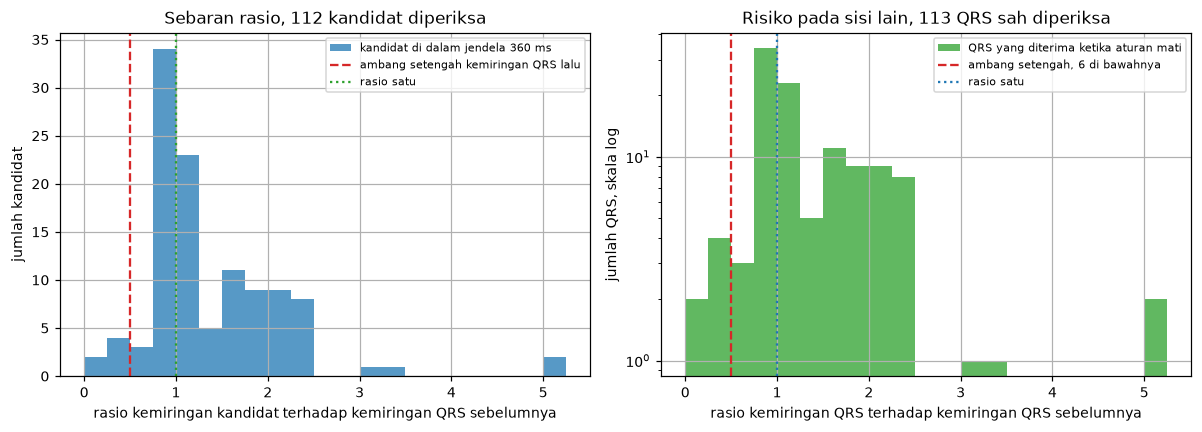

rasio kandidat di dalam pita: 112 nilai, dari 0.1374 sampai 5.2193
rasio QRS sah: 113 nilai, 6 di antaranya kurang dari setengah


In [13]:
# Tujuan: menggambar sebaran rasio kemiringan kandidat terhadap kemiringan QRS sebelumnya pada
# rekaman AFDB 04015, beserta garis setengah yang menjadi ambang aturan.
# Cell ini menghasilkan satu gambar dengan dua panel.

# ==== CELL 22: sebaran rasio kemiringan ====
rasio = UKUR["tidak"]["on"]["rasio_pita"]
rasio_sah = UKUR["tidak"]["off"]["rasio_qrs"]
fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.0))
ax[0].hist(rasio, bins=np.arange(0.0, 5.5, 0.25), color="C0", alpha=0.75, label="kandidat di dalam jendela 360 ms")
ax[0].axvline(0.5, color="C3", ls="--", label="ambang setengah kemiringan QRS lalu")
ax[0].axvline(1.0, color="C2", ls=":", label="rasio satu")
ax[0].set_xlabel("rasio kemiringan kandidat terhadap kemiringan QRS sebelumnya")
ax[0].set_ylabel("jumlah kandidat")
ax[0].set_title("Sebaran rasio, %d kandidat diperiksa" % rasio.size)
ax[0].legend(fontsize=7)
ax[1].hist(rasio_sah, bins=np.arange(0.0, 5.5, 0.25), color="C2", alpha=0.75,
           label="QRS yang diterima ketika aturan mati")
ax[1].axvline(0.5, color="C3", ls="--", label="ambang setengah, %d di bawahnya" % UKUR["tidak"]["off"]["berisiko"])
ax[1].axvline(1.0, color="C0", ls=":", label="rasio satu")
ax[1].set_yscale("log")
ax[1].set_xlabel("rasio kemiringan QRS terhadap kemiringan QRS sebelumnya")
ax[1].set_ylabel("jumlah QRS, skala log")
ax[1].set_title("Risiko pada sisi lain, %d QRS sah diperiksa" % rasio_sah.size)
ax[1].legend(fontsize=7)
fig.tight_layout()
plt.show()
print("rasio kandidat di dalam pita: %d nilai, dari %.4f sampai %.4f" % (
    rasio.size, float(rasio.min()), float(rasio.max())))
print("rasio QRS sah: %d nilai, %d di antaranya kurang dari setengah" % (
    rasio_sah.size, int(np.count_nonzero(rasio_sah < 0.5))))

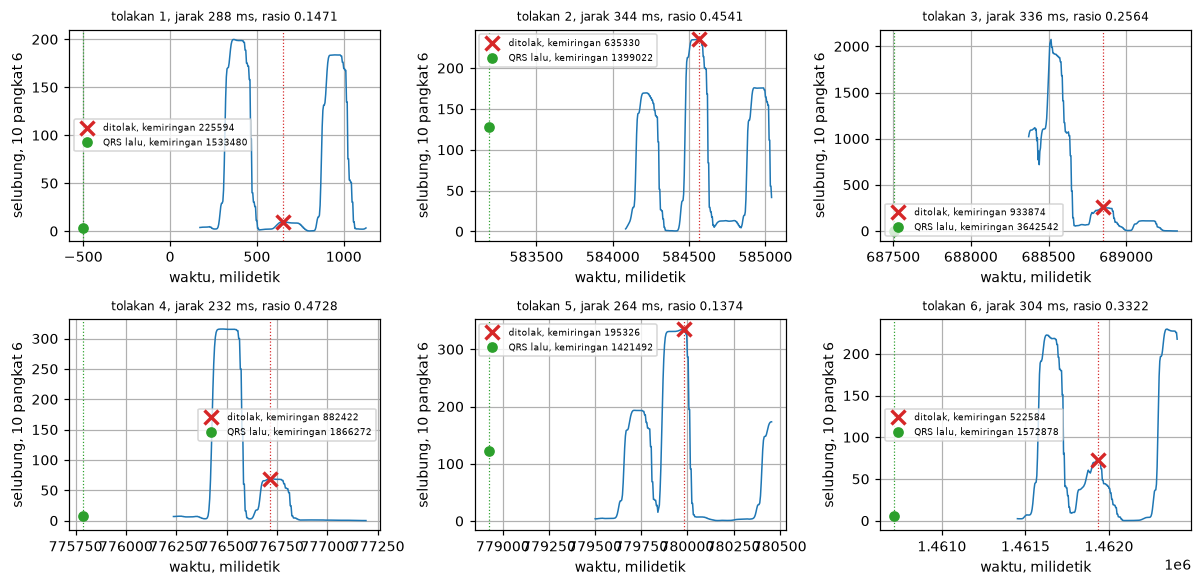

potongan yang digambar 6 dari 6 tolakan


In [14]:
# Tujuan: menggambar panel yang memperlihatkan puncak mana yang ditolak, yaitu enam potongan
# selubung di sekitar puncak yang ditolak oleh aturan gelombang T pada rekaman 04015.
# Cell ini menghasilkan satu gambar dengan enam panel.

# ==== CELL 23: potongan selubung puncak yang ditolak ====
tolakan = UKUR["tidak"]["on"]["tolakan"]
fig, ax = plt.subplots(2, 3, figsize=(11.0, 5.4))
for k, (p, kem_t, kem_q, rasio_t, dt) in enumerate(tolakan[:6]):
    a = max(0, int(p) - 120)
    b = min(sel.size, int(p) + 120)
    axk = ax[k // 3][k % 3]
    axk.plot(np.arange(a, b) / FS * 1000.0, sel[a:b] / 1e6, color="C0", lw=1.0)
    axk.plot([p / FS * 1000.0], [sel[int(p)] / 1e6], "x", color="C3", ms=9, mew=2.2,
             label="ditolak, kemiringan %d" % kem_t)
    axk.plot([(p - dt) / FS * 1000.0], [sel[int(p - dt)] / 1e6], "o", color="C2", ms=6,
             label="QRS lalu, kemiringan %d" % kem_q)
    axk.axvline((p - dt) / FS * 1000.0, color="C2", ls=":", lw=0.8)
    axk.axvline(p / FS * 1000.0, color="C3", ls=":", lw=0.8)
    axk.set_title("tolakan %d, jarak %.0f ms, rasio %.4f" % (k + 1, dt, rasio_t), fontsize=8)
    axk.set_xlabel("waktu, milidetik")
    axk.set_ylabel("selubung, 10 pangkat 6")
    axk.legend(fontsize=6)
fig.tight_layout()
plt.show()
print("potongan yang digambar %d dari %d tolakan" % (min(6, len(tolakan)), len(tolakan)))

In [15]:
# Tujuan: mengukur apakah puncak yang ditolak aturan itu denyut sungguhan atau bukan, dinilai
# terhadap deret acuan NeuroKit pantompkins1985 pada sinyal yang sama, dan mencetak kecocokan
# kedua deret pada tingkat 100 milidetik.
# Cell ini mencetak tabel jarak tiap tolakan ke denyut acuan terdekat.

# ==== CELL 24: tolakan dinilai terhadap deret acuan NeuroKit ====
pos_acuan = puncak_acuan
j2 = np.searchsorted(pos_acuan, qrs_mati)
jarak_acuan = []
for k, q in enumerate(qrs_mati):
    kandidat = [pos_acuan[max(j2[k] - 1, 0)], pos_acuan[min(j2[k], pos_acuan.size - 1)]]
    jarak_acuan.append(min(abs(int(q) - int(c)) for c in kandidat) / FS * 1000.0)
jarak_acuan = np.array(jarak_acuan)
print("denyut detektor yang cocok deret acuan dalam 100 milidetik: %d dari %d (%.4f)" % (
    int(np.count_nonzero(jarak_acuan <= 100.0)), qrs_mati.size,
    float(np.mean(jarak_acuan <= 100.0))))
print("median jarak denyut detektor ke acuan: %.1f milidetik" % float(np.median(jarak_acuan)))
print()
print("| tolakan | posisi (ms) | jarak ke denyut acuan terdekat (ms) | cocok dalam 100 ms |")
print("|---|---|---|---|")
tolakan_tidak = UKUR["tidak"]["on"]["tolakan"]
tolakan_paksa = UKUR["paksa"]["on"]["tolakan"]
for k, (p, kem_t, kem_q, rasio_t, dt) in enumerate(tolakan_tidak):
    j = int(np.searchsorted(pos_acuan, p))
    kandidat = [pos_acuan[max(j - 1, 0)], pos_acuan[min(j, pos_acuan.size - 1)]]
    terdekat = min(kandidat, key=lambda c: abs(int(c) - int(p)))
    jr = abs(int(p) - int(terdekat)) / FS * 1000.0
    print("| %d | %.1f | %.1f | %s |" % (k + 1, p / FS * 1000.0, jr, "ya" if jr <= 100.0 else "tidak"))
for k, (p, kem_t, kem_q, rasio_t, dt) in enumerate(tolakan_paksa):
    if any(abs(p - x[0]) < 2 for x in tolakan_tidak):
        continue
    j = int(np.searchsorted(pos_acuan, p))
    kandidat = [pos_acuan[max(j - 1, 0)], pos_acuan[min(j, pos_acuan.size - 1)]]
    terdekat = min(kandidat, key=lambda c: abs(int(c) - int(p)))
    jr = abs(int(p) - int(terdekat)) / FS * 1000.0
    print("| %d (separuh hidup) | %.1f | %.1f | %s |" % (k + 1, p / FS * 1000.0, jr, "ya" if jr <= 100.0 else "tidak"))
cocok_tolakan = []
for p, kem_t, kem_q, rasio_t, dt in tolakan_tidak:
    j = int(np.searchsorted(pos_acuan, p))
    kandidat = [pos_acuan[max(j - 1, 0)], pos_acuan[min(j, pos_acuan.size - 1)]]
    cocok_tolakan.append(min(abs(int(p) - int(c)) for c in kandidat) / FS * 1000.0)
cocok_tolakan = np.array(cocok_tolakan)
print()
print("tolakan yang jaraknya lebih dari 100 milidetik dari denyut acuan: %d dari %d" % (
    int(np.count_nonzero(cocok_tolakan > 100.0)), cocok_tolakan.size))
print("jarak terkecil tolakan ke denyut acuan: %.1f milidetik" % float(cocok_tolakan.min()))
HASIL["cocok acuan"] = float(np.mean(jarak_acuan <= 100.0))
HASIL["tolakan cocok acuan"] = int(np.count_nonzero(cocok_tolakan <= 100.0))
HASIL["tolakan jarak terkecil"] = float(cocok_tolakan.min())

denyut detektor yang cocok deret acuan dalam 100 milidetik: 1720 dari 2603 (0.6608)
median jarak denyut detektor ke acuan: 80.0 milidetik

| tolakan | posisi (ms) | jarak ke denyut acuan terdekat (ms) | cocok dalam 100 ms |
|---|---|---|---|
| 1 | 652.0 | 224.0 | tidak |
| 2 | 584564.0 | 108.0 | tidak |
| 3 | 688852.0 | 300.0 | tidak |
| 4 | 776716.0 | 280.0 | tidak |
| 5 | 779980.0 | 352.0 | tidak |
| 6 | 1461932.0 | 112.0 | tidak |
| 2 (separuh hidup) | 1172.0 | 260.0 | tidak |
| 3 (separuh hidup) | 1844.0 | 412.0 | tidak |
| 6 (separuh hidup) | 744116.0 | 352.0 | tidak |
| 9 (separuh hidup) | 794284.0 | 336.0 | tidak |
| 10 (separuh hidup) | 1094124.0 | 376.0 | tidak |

tolakan yang jaraknya lebih dari 100 milidetik dari denyut acuan: 6 dari 6
jarak terkecil tolakan ke denyut acuan: 108.0 milidetik


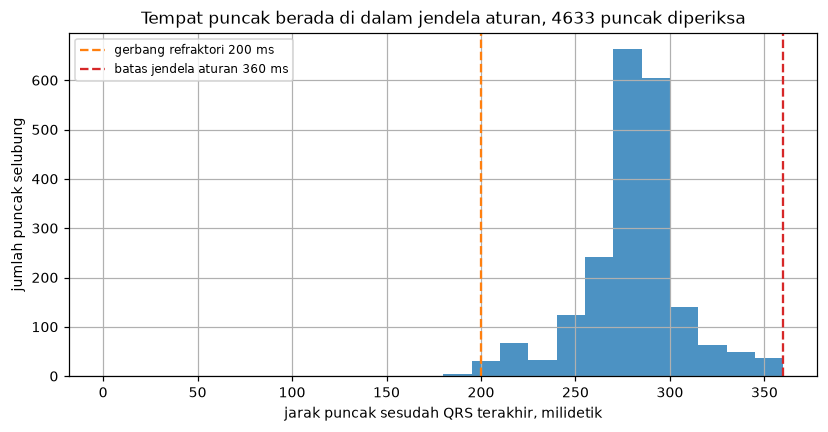

puncak di dalam jendela aturan 4633, di dalam pita 200 sampai 360 ms 2027, di dalam gerbang refraktori 5
fraksi puncak jendela aturan yang jatuh di dalam pita: 0.4375


In [16]:
# Tujuan: menggambar sebaran jarak puncak selubung sesudah QRS pada rekaman 04015, dengan garis
# batas gerbang refraktori 200 milidetik dan jendela aturan 360 milidetik.
# Cell ini menghasilkan satu gambar dengan satu panel.

# ==== CELL 25: sebaran jarak puncak sesudah QRS ====
fig, ax = plt.subplots(figsize=(7.6, 4.0))
ax.hist(jarak_puncak, bins=np.arange(0, 366, 15), color="C0", alpha=0.8)
ax.axvline(PITA_MS[0], color="C1", ls="--", label="gerbang refraktori 200 ms")
ax.axvline(PITA_MS[1], color="C3", ls="--", label="batas jendela aturan 360 ms")
ax.set_xlabel("jarak puncak sesudah QRS terakhir, milidetik")
ax.set_ylabel("jumlah puncak selubung")
ax.set_title("Tempat puncak berada di dalam jendela aturan, %d puncak diperiksa" % jarak_puncak.size)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("puncak di dalam jendela aturan %d, di dalam pita 200 sampai 360 ms %d, di dalam gerbang refraktori %d" % (
    jarak_puncak.size, pita_t, pita_refr))
print("fraksi puncak jendela aturan yang jatuh di dalam pita: %.4f" % (pita_t / jarak_puncak.size))

## 10. Gerbang AND pada jendela kelas irama dengan ambang yang diturunkan ulang

Aturan gelombang T mengubah deret denyut, dan deret denyut adalah masukan fitur irama, jadi
pertanyaan yang harus dijawab adalah apakah gerbang AND yang sudah ada ikut berubah. Gerbang AND
itu berbunyi RMSSD dibagi rata-rata RR lebih besar daripada satu ambang DAN entropi ternormalisasi
lebih besar daripada ambang kedua, dihitung pada jendela 32 denyut berlangkah 4 denyut, dengan
label kelas diambil dari anotasi irama resmi rekaman dan hanya jendela yang seluruh 32 denyutnya
satu kelas yang dipakai.

Angka acuan yang sudah terkunci diukur pada deret acuan NeuroKit dengan ambang lama, dan angka itu
dicetak ulang hanya sebagai pemeriksaan bahwa perangkat ukur fiturnya sama. Yang diukur di sini
adalah deret detektor sendiri, pada dua keadaan aturan gelombang T: hidup sebagai bawaan P5-1 dan
mati sebagai pembanding. Pasangan ambang gerbang untuk kedua keadaan itu **diturunkan ulang pada
deret detektor sendiri**, yaitu dengan menyapu kisi ambang rasio dan ambang entropi pada deret itu
lalu memilih pasangan dengan akurasi terbesar.

**Ambang lama 0,70 tidak boleh dipindahkan.** Ambang itu diukur pada deret acuan, sedangkan median
entropi kelas N pada deret detektor sendiri jauh lebih rendah daripada pada deret acuan. Sel
berikutnya mencetak median entropi kedua deret itu dan mencetak akibat terukurnya bila ambang lama
dipindahkan apa adanya, sehingga alasan larangan itu berdiri di atas angka, bukan di atas dugaan.
Seluruh angka kepekaan, spesifisitas, akurasi, dan jumlah jendela yang dilaporkan di bagian ini
memakai ambang hasil turunan, bukan ambang lama.

In [17]:
# Tujuan: mengukur fitur irama dan gerbang AND pada tiga deret denyut, yaitu deret acuan NeuroKit,
# deret detektor dengan aturan gelombang T hidup sebagai bawaan P5-1, dan deret detektor dengan
# aturan mati, memakai ambang gerbang yang diturunkan ulang pada deret detektor sendiri.
# Cell ini mencetak tabel jendela, tabel AUC, tabel ambang hasil turunan, dan catatan ambang lama.

# ==== CELL 27: gerbang AND dengan ambang yang diturunkan ulang pada deret detektor ====
JENDELA_DENYUT = 32
LANGKAH_DENYUT = 4
AMBANG_LAMA_RASIO = 0.21            # ambang lama pada deret acuan
AMBANG_LAMA_ENTROPI = 0.70          # ambang lama pada deret acuan, tidak boleh dipindahkan


def label_irama(ann, n):
    lab = np.array([""] * n, dtype=object)
    cur = ""
    for t, nt in zip(ann.sample, ann.aux_note):
        if nt:
            s = nt.strip()
            if s.startswith("("):
                cur = s.strip("(").strip(")")
        if 0 <= t < n:
            lab[t:] = cur
    return lab


def fitur_irama(rr_ms):
    rr = np.asarray(rr_ms, float)
    d = np.diff(rr)
    rmssd = float(np.sqrt(np.mean(d ** 2)))
    pnn50 = float(np.mean(np.abs(d) > 50.0))
    s = np.sort(rr)
    core = s[8:-8] if s.size > 20 else s
    edges = np.linspace(core.min(), core.max(), 17)
    edges[-1] += 1e-9
    cnt, _ = np.histogram(core, bins=edges)
    p = cnt[cnt > 0] / cnt.sum()
    h = float(-(p * np.log2(p)).sum())
    return rmssd, rmssd / rr.mean(), pnn50, h / 4.0


def auc_rank(x, y):
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    r = np.argsort(np.concatenate([x, y])).argsort() + 1
    return float((r[:x.size].sum() - x.size * (x.size + 1) / 2) / (x.size * y.size))


def kumpulkan_jendela(peaks, lab):
    rr = np.diff(peaks) / FS * 1000.0
    bl = lab[peaks[1:]]
    baris = []
    for i in range(0, rr.size - JENDELA_DENYUT, LANGKAH_DENYUT):
        seg = rr[i:i + JENDELA_DENYUT]
        u = np.unique(bl[i:i + JENDELA_DENYUT])
        if u.size != 1 or u[0] not in ("AFIB", "N"):
            continue
        if seg.min() < 200 or seg.max() > 3000:
            continue
        baris.append((u[0], *fitur_irama(seg)))
    arr = np.array([[b[1], b[2], b[3], b[4]] for b in baris], float)
    cls = np.array([b[0] for b in baris])
    return arr, cls


def nilai_gerbang(arr, cls, t1, t2):
    """Gerbang AND berbunyi rasio RMSSD lebih besar daripada t1 DAN entropi lebih besar daripada t2."""
    af = cls == "AFIB"
    p = (arr[:, 1] > t1) & (arr[:, 3] > t2)
    return dict(kepekaan=float(p[af].mean()), spesifisitas=float(1.0 - p[~af].mean()),
                akurasi=float((p == af).mean()), jendela=int(cls.size),
                afib=int(af.sum()), n=int((~af).sum()))


def turunkan_ambang(arr, cls, kisi1, kisi2):
    """Turunkan pasangan ambang gerbang AND pada deret itu sendiri.

    Aturan pemilihan: akurasi terbesar, lalu Youden terbesar, lalu ambang terkecil, supaya hasilnya
    satu pasangan saja dan tidak bergantung urutan sapuan. Ketika beberapa pasangan mencapai akurasi
    terbesar, jumlah pasangan yang seri dan rentang ambang entropinya dilaporkan terpisah.
    """
    af = cls == "AFIB"
    seri = []
    for t1 in kisi1:
        m1 = arr[:, 1] > t1
        for t2 in kisi2:
            p = m1 & (arr[:, 3] > t2)
            se = float(p[af].mean())
            sp = float(1.0 - p[~af].mean())
            acc = float((p == af).mean())
            youden = se + sp - 1.0
            seri.append((acc, youden, float(t1), float(t2), se, sp))
    acc_max = max(s[0] for s in seri)
    seri = [s for s in seri if s[0] >= acc_max - 1e-12]
    seri.sort(key=lambda s: (-s[1], s[2], s[3]))
    acc, youden, t1, t2, se, sp = seri[0]
    return dict(t1=t1, t2=t2, kepekaan=se, spesifisitas=sp, akurasi=acc, youden=youden,
                jendela=int(cls.size), afib=int(af.sum()), n=int((~af).sum()),
                seri=len(seri), t2_min=min(s[3] for s in seri), t2_max=max(s[3] for s in seri),
                t1_max=max(s[2] for s in seri))


anotasi = wfdb.rdann(str(REKAMAN), "atr")
lab = label_irama(anotasi, 450000)
GERBANG = {}
DERET_GERBANG = (("acuan NeuroKit", puncak_acuan),
                 ("detektor aturan hidup", np.array(UKUR["tidak"]["on"]["qrs"], dtype=np.int64)),
                 ("detektor aturan mati", np.array(UKUR["tidak"]["off"]["qrs"], dtype=np.int64)))
print("| deret denyut | denyut | jendela | AFIB | N | AUC rasio | AUC entropi | median entropi AFIB | median entropi N |")
print("|---|---|---|---|---|---|---|---|---|")
for nama, peaks in DERET_GERBANG:
    arr, cls = kumpulkan_jendela(peaks, lab)
    af = cls == "AFIB"
    GERBANG[nama] = dict(arr=arr, cls=cls,
                         auc=[auc_rank(arr[af, j], arr[~af, j]) for j in range(4)],
                         ent_af=float(np.median(arr[af, 3])), ent_n=float(np.median(arr[~af, 3])))
    print("| %s | %d | %d | %d | %d | %.4f | %.4f | %.4f | %.4f |" % (
        nama, peaks.size, cls.size, int(af.sum()), int((~af).sum()), GERBANG[nama]["auc"][1],
        GERBANG[nama]["auc"][3], GERBANG[nama]["ent_af"], GERBANG[nama]["ent_n"]))
print()
print("AUC empat fitur pada tiap deret, urutan RMSSD, RMSSD dibagi rata-rata, pNN50, entropi ternormalisasi:")
for nama, g in GERBANG.items():
    print("  %-24s %s" % (nama, " ".join("%.4f" % v for v in g["auc"])))
print()
kisi1 = np.arange(0.00, 0.62, 0.005)
kisi2 = np.arange(0.02, 0.99, 0.01)
print("jendela fitur irama: %d denyut berlangkah %d denyut, dan hanya jendela satu kelas yang dipakai" % (
    JENDELA_DENYUT, LANGKAH_DENYUT))
print("kisi turunan ambang: rasio RMSSD bagi rata-rata dari %.3f sampai %.3f langkah %.3f, dan entropi" % (
    kisi1[0], kisi1[-1], kisi1[1] - kisi1[0]))
print("ternormalisasi dari %.2f sampai %.2f langkah %.2f, seluruhnya pada deret detektor itu sendiri" % (
    kisi2[0], kisi2[-1], kisi2[1] - kisi2[0]))
print("| deret detektor | aturan | ambang rasio | ambang entropi | kepekaan | spesifisitas | akurasi | jendela | AFIB | N |")
print("|---|---|---|---|---|---|---|---|---|---|")
AMBANG = {}
for nama, kunci in (("detektor aturan hidup", "hidup"), ("detektor aturan mati", "mati")):
    g = GERBANG[nama]
    s = turunkan_ambang(g["arr"], g["cls"], kisi1, kisi2)
    AMBANG[kunci] = s
    print("| %s | %s | %.3f | %.2f | %.2f%% | %.2f%% | %.2f%% | %d | %d | %d |" % (
        nama, kunci, s["t1"], s["t2"], s["kepekaan"] * 100, s["spesifisitas"] * 100,
        s["akurasi"] * 100, s["jendela"], s["afib"], s["n"]))
print()
for kunci in ("hidup", "mati"):
    s = AMBANG[kunci]
    print("deret detektor aturan %-5s: %d pasangan ambang mencapai akurasi terbesar yang sama, ambang rasio" % (
        kunci, s["seri"]))
    print("  terbesar di antara pasangan seri itu %.3f, dan ambang entropi bergerak dari %.2f sampai %.2f." % (
        s["t1_max"], s["t2_min"], s["t2_max"]))
print("karena ambang rasio terbaik jatuh di ujung bawah kisi, syarat rasio pada deret detektor sendiri tidak")
print("lagi menyaring apa pun, dan gerbang yang tinggal berlaku adalah syarat entropi. Angka kepekaan dan")
print("spesifisitas di atas tetap dilaporkan apa adanya sebagai hasil gerbang AND yang diturunkan ulang.")
print()
print("ambang lama pada deret acuan, nilai rasio %.2f dan nilai entropi %.2f, hanya sebagai acuan angka terkunci:" % (
    AMBANG_LAMA_RASIO, AMBANG_LAMA_ENTROPI))
a = GERBANG["acuan NeuroKit"]
lama = nilai_gerbang(a["arr"], a["cls"], AMBANG_LAMA_RASIO, AMBANG_LAMA_ENTROPI)
print("  deret acuan NeuroKit dengan ambang lama: kepekaan %.2f%%, spesifisitas %.2f%%, akurasi %.2f%%, jendela %d" % (
    lama["kepekaan"] * 100, lama["spesifisitas"] * 100, lama["akurasi"] * 100, lama["jendela"]))
h = GERBANG["detektor aturan hidup"]
lama_hidup = nilai_gerbang(h["arr"], h["cls"], AMBANG_LAMA_RASIO, AMBANG_LAMA_ENTROPI)
campur = nilai_gerbang(h["arr"], h["cls"], AMBANG["hidup"]["t1"], AMBANG_LAMA_ENTROPI)
print("  ambang lama bila dipindahkan apa adanya ke deret detektor aturan hidup: kepekaan %.2f%%, spesifisitas %.2f%%, akurasi %.2f%%" % (
    lama_hidup["kepekaan"] * 100, lama_hidup["spesifisitas"] * 100, lama_hidup["akurasi"] * 100))
print("  ambang rasio hasil turunan dengan ambang entropi lama %.2f saja: kepekaan %.2f%%, spesifisitas %.2f%%, akurasi %.2f%%" % (
    AMBANG_LAMA_ENTROPI, campur["kepekaan"] * 100, campur["spesifisitas"] * 100, campur["akurasi"] * 100))
print("  selisih terhadap gerbang hasil turunan penuh %.2f poin datang dari syarat rasio lama, dan selisih %.2f poin" % (
    (AMBANG["hidup"]["akurasi"] - campur["akurasi"]) * 100, (campur["akurasi"] - lama_hidup["akurasi"]) * 100))
print("  sisanya datang dari syarat entropi lama, jadi kedua syarat lama itu ikut menurunkan akurasi.")
print("  ambang lama 0,70 untuk entropi tidak boleh dipindahkan ke deret detektor sendiri, karena median entropi")
print("  kelas N pada deret detektor %.4f jauh lebih rendah daripada pada deret acuan %.4f; angka gerbang yang" % (
    h["ent_n"], a["ent_n"]))
print("  dilaporkan di atas adalah ambang yang diturunkan ulang pada deret detektor sendiri, dan pemindahan")
print("  ambang lama apa adanya terukur menurunkan akurasi dari %.2f%% menjadi %.2f%%." % (
    AMBANG["hidup"]["akurasi"] * 100, lama_hidup["akurasi"] * 100))
print()
print("selisih deret detektor hidup dikurangi mati, keduanya dengan ambang hasil turunan sendiri:")
for k, v in (("kepekaan", "kepekaan"), ("spesifisitas", "spesifisitas"), ("akurasi", "akurasi")):
    print("  %-13s %+.2f poin" % (k, (AMBANG["hidup"][v] - AMBANG["mati"][v]) * 100))
print("  jendela       hidup %d, mati %d" % (AMBANG["hidup"]["jendela"], AMBANG["mati"]["jendela"]))
HASIL["gerbang hidup rasio"] = float(AMBANG["hidup"]["t1"])
HASIL["gerbang hidup entropi"] = float(AMBANG["hidup"]["t2"])
HASIL["gerbang hidup kepekaan"] = float(AMBANG["hidup"]["kepekaan"])
HASIL["gerbang hidup spesifisitas"] = float(AMBANG["hidup"]["spesifisitas"])
HASIL["gerbang hidup akurasi"] = float(AMBANG["hidup"]["akurasi"])
HASIL["gerbang hidup jendela"] = int(AMBANG["hidup"]["jendela"])
HASIL["gerbang hidup pasangan seri"] = int(AMBANG["hidup"]["seri"])
HASIL["gerbang hidup entropi seri maksimum"] = float(AMBANG["hidup"]["t2_max"])
HASIL["gerbang mati rasio"] = float(AMBANG["mati"]["t1"])
HASIL["gerbang mati entropi"] = float(AMBANG["mati"]["t2"])
HASIL["gerbang mati kepekaan"] = float(AMBANG["mati"]["kepekaan"])
HASIL["gerbang mati spesifisitas"] = float(AMBANG["mati"]["spesifisitas"])
HASIL["gerbang mati akurasi"] = float(AMBANG["mati"]["akurasi"])
HASIL["gerbang mati jendela"] = int(AMBANG["mati"]["jendela"])
HASIL["gerbang acuan kepekaan"] = float(lama["kepekaan"])
HASIL["gerbang acuan spesifisitas"] = float(lama["spesifisitas"])
HASIL["gerbang acuan akurasi"] = float(lama["akurasi"])
HASIL["gerbang acuan jendela"] = int(lama["jendela"])
HASIL["gerbang lama pada detektor hidup"] = float(lama_hidup["akurasi"])
HASIL["gerbang campur akurasi"] = float(campur["akurasi"])
HASIL["gerbang entropi N detektor"] = float(h["ent_n"])
HASIL["gerbang entropi N acuan"] = float(a["ent_n"])

| deret denyut | denyut | jendela | AFIB | N | AUC rasio | AUC entropi | median entropi AFIB | median entropi N |
|---|---|---|---|---|---|---|---|---|


| acuan NeuroKit | 2601 | 590 | 95 | 495 | 0.7699 | 0.9045 | 0.8007 | 0.6506 |
| detektor aturan hidup | 2596 | 588 | 95 | 493 | 0.7822 | 0.9523 | 0.7812 | 0.3119 |
| detektor aturan mati | 2603 | 593 | 97 | 496 | 0.7739 | 0.9474 | 0.7695 | 0.3119 |

AUC empat fitur pada tiap deret, urutan RMSSD, RMSSD dibagi rata-rata, pNN50, entropi ternormalisasi:
  acuan NeuroKit           0.6337 0.7699 0.8278 0.9045
  detektor aturan hidup    0.6664 0.7822 0.8631 0.9523
  detektor aturan mati     0.6533 0.7739 0.8529 0.9474

jendela fitur irama: 32 denyut berlangkah 4 denyut, dan hanya jendela satu kelas yang dipakai
kisi turunan ambang: rasio RMSSD bagi rata-rata dari 0.000 sampai 0.615 langkah 0.005, dan entropi
ternormalisasi dari 0.02 sampai 0.98 langkah 0.01, seluruhnya pada deret detektor itu sendiri
| deret detektor | aturan | ambang rasio | ambang entropi | kepekaan | spesifisitas | akurasi | jendela | AFIB | N |
|---|---|---|---|---|---|---|---|---|---|


| detektor aturan hidup | hidup | 0.000 | 0.69 | 92.63% | 89.66% | 90.14% | 588 | 95 | 493 |


| detektor aturan mati | mati | 0.000 | 0.70 | 87.63% | 90.32% | 89.88% | 593 | 97 | 496 |

deret detektor aturan hidup: 75 pasangan ambang mencapai akurasi terbesar yang sama, ambang rasio
  terbesar di antara pasangan seri itu 0.185, dan ambang entropi bergerak dari 0.69 sampai 0.73.
deret detektor aturan mati : 35 pasangan ambang mencapai akurasi terbesar yang sama, ambang rasio
  terbesar di antara pasangan seri itu 0.170, dan ambang entropi bergerak dari 0.70 sampai 0.70.
karena ambang rasio terbaik jatuh di ujung bawah kisi, syarat rasio pada deret detektor sendiri tidak
lagi menyaring apa pun, dan gerbang yang tinggal berlaku adalah syarat entropi. Angka kepekaan dan
spesifisitas di atas tetap dilaporkan apa adanya sebagai hasil gerbang AND yang diturunkan ulang.

ambang lama pada deret acuan, nilai rasio 0.21 dan nilai entropi 0.70, hanya sebagai acuan angka terkunci:
  deret acuan NeuroKit dengan ambang lama: kepekaan 92.63%, spesifisitas 79.60%, akurasi 81.69%, jendela 590
  

## 11. Catatan fixed-point memakai konvensi terkunci

Konvensi di bawah ini dikunci di [[afib-lite/34 - Spesifikasi Produk Terkunci, Rencana Fase, dan
Perubahan Breakdown]], bagian 3.7, dan dipakai seluruh fase. Tahap ini berada di ujung rantai,
sesudah turunan, sehingga seluruh skalanya ditentukan keputusan sebelumnya.

1. Masukan rentangnya plus minus 5 mV dengan 12 bit signifikan, dijepit pada plus minus 2047
   hitungan, lalu digeser ke kiri 4 bit.
2. Sesudah turunan lima titik, hasilnya digeser kanan 8 bit, sehingga faktor skala ambangnya 256.
3. Kuadrat dan jendela 32 bit, jendela bergantian 37 dan 38 sampel, penampan melingkar.
4. Pembagian dengan 38 tidak dilakukan di RTL, sehingga ambangnya dikalikan 38.
5. RR dihitung dalam milidetik bulat pada notebook ini, karena ketiga batas halaman 234 ditulis
   dalam milidetik; lebar bit yang dibutuhkan oleh interval RR terbesar di dalam topeng 250 sampai
   2000 milidetik terukur di bagian 9 pada deret RR rekaman uji, dan keputusan satuan sampel fase 4
   dipakai apa adanya di notebook fase 4.
6. Penjaga gerbang refraktori 200 milidetik dan jendela 360 milidetik memerlukan satu penghitung
   sampel bersama, dan penghitung itu tidak boleh direset oleh puncak yang ditolak.
7. Jendela kemiringan lebar 37 sampel, keputusan P5-4, memerlukan penampan melingkar kedua yang
   menyimpan keluaran turunan; karena kemiringan QRS sebelumnya dibandingkan dengan kemiringan
   puncak yang sedang dinilai, penampan itu harus tetap memuat keluaran turunan yang belum digeser.
8. Aturan penyemaian ulang memerlukan riwayat 32 interval RR terakhir dan satu operasi median atas
   riwayat itu, yang di RTL dijalankan sebagai jaringan pembanding dan bukan sebagai pembagian;
   kedalaman riwayat 32 interval dan batas sekali per 8 denyut keduanya adalah tetapan terkunci.

Bentuk uji yang dikunci untuk tahap ini adalah bentuk silang dari keputusan P5-3:

$$
2 s < s_{prev}
$$

Dengan bentuk itu tidak ada pembagian dan tidak ada pembulatan pada uji keputusan: pembandingnya
hanya perlu satu bit tambahan di sisi kiri. Kemiringan yang dibandingkan boleh diambil sebelum
atau sesudah geser kanan delapan bit asalkan kedua sisi diambil dari titik yang sama, karena
penggeseran kanan yang sama pada dua sisi tidak mengubah hasil perbandingan selama tidak ada bit
yang terbuang. Yang perlu dijaga hanya satu: kemiringan QRS sebelumnya harus disimpan sebagai
besaran yang belum digeser, karena geser kanan yang diterapkan pada nilai yang sudah menyusut
kehilangan lebih banyak bit.

Bila tim lebih suka menghindari penambahan satu bit pada pembanding, cadangan yang sama eksaknya
adalah bentuk geser dibulatkan:

$$
s < \left( \left( s_{prev} + 1 \right) \gg 1 \right)
$$

Biayanya satu penjumlah pada nilai yang disimpan, dan hasilnya eksak pada seluruh kisi uji.
Cadangan itu dicatat di sini sebagai pilihan tim, sedangkan bentuk silang tetap bentuk bawaan
sesuai keputusan P5-3.

## 12. Hubungan ke rancangan AFIB-LITE dan keputusan yang sudah dikunci

Empat akibat rancangan yang langsung terbaca dari pengukuran di notebook ini.

1. Aturan gelombang T wajib ada, tetapi ia bukan pengganti pengkuadratan dan jendela integrasi.
   Angka pendukungnya diukur di notebook pengkuadratan dan jendela integrasi, karena pengkuadratan
   bekerja pada amplitudo sedangkan aturan ini bekerja pada keputusan, dan kedua lapisan itu
   berurutan.
2. Aturan ini hanya bermakna di dalam pita 200 sampai 360 milidetik. Di dalam gerbang refraktori
   200 milidetik puncaknya sudah ditolak lebih dulu, sedangkan di luar 360 milidetik aturan buta
   dan puncak lemah apa pun diterima asalkan lolos ambang. Jadi yang harus dipasang di RTL adalah
   dua pencacah jarak, satu pencacah 200 milidetik dan satu pencacah 360 milidetik, bukan satu
   gerbang tunggal.
3. Lebar jendela kemiringan adalah keputusan tim, bukan keputusan makalah. Notebook menyapu lima
   lebar jendela pada rekaman nyata dan hasilnya bukan monoton: lebar jendela 75 sampai 149 sampel
   paling sedikit menolak, sedangkan lebar 11 sampel paling banyak menolak. Lebar 37 sampel dipakai
   karena sama dengan lebar jendela integrasi terkunci, dan pilihan itu dikunci sebagai P5-4.
4. Besaran kemiringan adalah keluaran tahap turunan lima titik, bukan beda EKG terfilter. Pada
   rekaman nyata kedua pilihan itu berbeda satu tolakan dan satu QRS berisiko, sedangkan pada
   sinyal buatan keduanya memberi jumlah gelombang T yang lolos sama, sehingga pilihan itu berdiri
   di atas kalimat halaman 232 dan atas jarak terhadap ambang yang lebih lebar pada bacaan turunan.

Satu catatan penutup untuk pembaca keluaran RTL. Puncak yang ditolak aturan ini bukan luaran, dan
penolakan itu juga bukan pembuangan data: puncak yang dinyatakan gelombang T masuk ke jalur derau
dan ikut menaikkan taksiran puncak derau persamaan (13) dan (18). Karena itu efek aturan ini pada
jumlah denyut lebih besar daripada jumlah penolakan yang tercetak di tabel, dan kedua angka itu
harus dilaporkan berpasangan.

**Enam keputusan terkunci tim pada 19 Oktober 2026.** Kelimanya keputusan baru fase ini ditambah
aturan penyemaian ulang dari fase 4, dan seluruhnya berpengaruh ke RTL dan ke kode host.

1. **P5-1, aturan gelombang T sebagai bawaan.** Aturan halaman 234 hidup secara bawaan di seluruh
   notebook ini, bukan lagi dipakai sebagai pembanding. Keadaan aturan mati hanya muncul di tempat
   yang keterangannya menulis pembanding secara eksplisit, misalnya pada tabel tukar menukar di
   bagian 7, pada tabel pemotongan separuh di bagian 9, dan pada tabel gerbang AND di bagian 10.
   Ukuran gerbang keputusan di bagian 10 karena itu dihitung ulang pada deret detektor sendiri
   untuk kedua keadaan.
2. **P5-2, besaran kemiringan.** Kemiringan diambil dari keluaran tahap turunan lima titik
   persamaan (9), dengan alasan halaman 232 dan dengan jarak terhadap ambang setengah yang lebih
   lebar daripada bacaan beda EKG terfilter. Beda EKG terfilter tinggal pembanding singkat di
   bagian 4 dan di bagian 8.
3. **P5-3, bentuk uji setengah kemiringan.** Bentuk yang diuji adalah bentuk silang
   $2 s < s_{prev}$ pada bilangan bulat, yang eksak pada seluruh kisi uji pasangan kemiringan.
   Bentuk geser ke bawah tidak eksak dan hanya dicatat sebagai pembanding, sedangkan bentuk geser
   dibulatkan sama eksaknya dengan bentuk silang dan dicatat sebagai cadangan berbiaya satu
   penjumlah.
4. **P5-4, lebar jendela kemiringan 37 sampel.** Halaman 234 tidak menentukan lebar itu, jadi
   lebar 37 sampel adalah pilihan tim dan ditulis sebagai tetapan bernama di sel pembuka. Pilihan
   itu sama dengan lebar jendela integrasi terkunci, sehingga penampan melingkar yang sama dapat
   dipakai ulang.
5. **P5-5, batas keberlakuan 0,90 milivolt.** Batas itu ditulis sebagai batas resmi di bagian 7,
   bukan sebagai catatan kaki, dan tiap baris sapuan amplitudo ditandai terhadap batas itu. Di
   bawah batas itu aturan menolak seluruh gelombang T palsu tanpa kehilangan QRS sah; di atas
   batas itu aturan harus didampingi pemeriksaan amplitudo tambahan.
6. **Aturan penyemaian ulang antrean delapan interval.** Bila tidak ada interval RR yang lolos
   pita 0,92 sampai 1,16 kali rata-rata kedua selama 8 denyut berturut-turut, antrean delapan
   interval diisi ulang memakai median 32 interval RR terakhir, lalu rata-rata kedua dihitung
   ulang dari antrean itu, dan penyemaian ulang dibatasi paling banyak sekali per 8 denyut. Dengan
   aturan ini penanda irama teratur persamaan (29) menyala 1.202 kali pada rekaman uji, sedangkan
   tanpa aturan itu penanda tersebut tidak menyala satu kali pun. Aturan ini juga mengubah deret
   sebelum aturan dari 2.605 denyut menjadi 2.603 denyut, sehingga angka acuan fase 4 harus dibaca
   bersama keadaan penyemaian ulangnya.

Yang masih terbuka untuk fase berikutnya, dan keduanya bukan bagian dari enam keputusan terkunci:
kebijakan kedalaman penampan puncak kandidat dari fase 4, dan perbaikan rantai ambang adaptif
karena pada rekaman uji deret interval RR-nya memuat interval di luar topeng, dengan jarak terbesar
sekitar 51 detik tanpa denyut.

## 13. Ringkasan seluruh angka terukur

Seluruh angka di bawah ini dicetak dari kamus hasil yang diisi sel-sel sebelumnya, sehingga tidak ada
angka yang ditulis ulang dengan tangan. Kunci kamusnya ditulis sama persis dengan kunci yang dipakai
sel penghasil, dan setiap nilai dibaca dengan toleransi larik bilangan bulat atau pembulatan cetak.

Angka-angka ini adalah angka keadaan terkunci. Lima keputusan P5-1 sampai P5-5 dan aturan penyemaian
ulang antrean interval RR dikunci tim pada **19 Oktober 2026**, semuanya dipakai sebagai bawaan di
seluruh perhitungan di atas, dan tidak ada satu pun dari keenamnya yang masih berupa pertanyaan
terbuka di notebook ini. Ringkasan keputusan itu beserta akibatnya pada rancangan ada di bagian 12.

In [18]:
# Tujuan: mencetak seluruh angka terukur di notebook ini sebagai satu tabel ringkasan, dibaca dari
# kamus hasil yang diisi sel-sel sebelumnya.
# Cell ini mencetak tabel ringkasan beserta jumlah kunci yang terisi.

# ==== CELL 31: ringkasan seluruh angka terukur ====
KUNCI = ["jumlah sel kode", "batas keberlakuan mV", "lebar jendela kemiringan",
         "puncak selubung", "selubung maksimum", "turunan maksimum", "sampel terjepit", "denyut acuan",
         "puncak dalam 360 ms", "puncak dalam pita 200-360", "denyut gerbang mati",
         "besaran turunan ditolak", "besaran beda ditolak", "osilang tidak cocok",
         "kisi silang tidak cocok", "kisi geser bawah tidak cocok",
         "deret buatan diterima hidup", "deret buatan diterima mati", "deret buatan T palsu",
         "buatan T salah diterima", "buatan T ditolak aturan", "buatan T lolos sesudah",
         "buatan denyut sebelum", "buatan denyut sesudah", "buatan qrs sebelum", "buatan qrs sesudah",
         "buatan acuan QRS", "buatan QRS hilang sebelum", "buatan QRS hilang sesudah",
         "buatan palsu turun", "buatan hilang bertambah",
         "beda cara T lolos turunan", "beda cara T lolos beda", "beda cara T lolos 0,70 turunan",
         "beda cara T lolos 0,70 beda", "nisbah rasio T terbesar", "rasio T turunan 0,70",
         "rasio T beda 0,70",
         "denyut sebelum", "denyut sesudah", "kolam sebelum", "kolam sesudah", "diperiksa", "ditolak",
         "berisiko", "rasio QRS berisiko", "denyut sebelum separuh", "denyut sesudah separuh",
         "kolam sebelum separuh", "kolam sesudah separuh", "ditolak separuh",
         "penanda hidup semai hidup", "penanda hidup semai mati", "penanda mati semai hidup",
         "langkah penanda hidup", "semai penanda hidup",
         "denyut sebelum semai mati", "denyut sebelum semai hidup",
         "RR terbesar ms", "RR lebar bit", "RR di luar topeng", "RR terbesar di luar topeng",
         "cocok acuan", "tolakan cocok acuan", "tolakan jarak terkecil",
         "gerbang hidup rasio", "gerbang hidup entropi", "gerbang hidup kepekaan",
         "gerbang hidup spesifisitas", "gerbang hidup akurasi", "gerbang hidup jendela",
         "gerbang hidup pasangan seri", "gerbang hidup entropi seri maksimum",
         "gerbang mati rasio", "gerbang mati entropi", "gerbang mati kepekaan",
         "gerbang mati spesifisitas", "gerbang mati akurasi", "gerbang mati jendela",
         "gerbang acuan kepekaan", "gerbang acuan spesifisitas", "gerbang acuan akurasi",
         "gerbang acuan jendela", "gerbang lama pada detektor hidup", "gerbang campur akurasi",
         "gerbang entropi N detektor", "gerbang entropi N acuan",
         "lingkar mati kolam", "lingkar hidup kolam", "lingkar mati penanda", "lingkar hidup penanda"]
print("| besaran | nilai |")
print("|---|---|")
for k in KUNCI:
    v = HASIL.get(k, "belum diisi")
    if isinstance(v, float):
        print("| %s | %.6f |" % (k, v))
    else:
        print("| %s | %s |" % (k, v))
terisi = sum(1 for k in KUNCI if k in HASIL)
print()
print("kunci terisi %d dari %d kunci ringkasan" % (terisi, len(KUNCI)))
print("jumlah sel kode yang dijanjikan cell pembuka: 18, seluruhnya dibuka blok komentar Tujuan")
print("jumlah gambar notebook ini: 5, satu gambar pada tiap sel yang menggambar")

| besaran | nilai |
|---|---|
| jumlah sel kode | 18 |
| batas keberlakuan mV | 0.900000 |
| lebar jendela kemiringan | 37 |
| puncak selubung | 4777 |
| selubung maksimum | 3105281786 |
| turunan maksimum | 4792318 |
| sampel terjepit | 402 |
| denyut acuan | 2601 |
| puncak dalam 360 ms | 4633 |
| puncak dalam pita 200-360 | 2027 |
| denyut gerbang mati | 2603 |
| besaran turunan ditolak | 6 |
| besaran beda ditolak | 7 |
| osilang tidak cocok | 0 |
| kisi silang tidak cocok | 0 |
| kisi geser bawah tidak cocok | 2048 |
| deret buatan diterima hidup | 5 |
| deret buatan diterima mati | 5 |
| deret buatan T palsu | 1 |
| buatan T salah diterima | 150 |
| buatan T ditolak aturan | 6 |
| buatan T lolos sesudah | 0 |
| buatan denyut sebelum | 299 |
| buatan denyut sesudah | 149 |
| buatan qrs sebelum | 149 |
| buatan qrs sesudah | 149 |
| buatan acuan QRS | 149 |
| buatan QRS hilang sebelum | 0 |
| buatan QRS hilang sesudah | 0 |
| buatan palsu turun | 150 |
| buatan hilang bertambah | 0

## 14. Rujukan

1. Pan J, Tompkins WJ. *A Real-Time QRS Detection Algorithm.* IEEE Transactions on Biomedical
   Engineering, 1985, BME-32(3):230-236. DOI 10.1109/TBME.1985.325532. Bagian `T-Wave Identification`
   beserta kalimat jendela 360 milidetik dan uji kemiringan separuh ada di halaman 234. Kalimat
   periode refraktori 200 milidetik ada di halaman 231, dan rumusan aturan yang lebih lengkap ada di
   halaman 232. Bagian `Derivative` dan paragraf yang menyebut tahap turunan sebagai pemberi
   informasi kemiringan kompleks QRS ada di halaman 232, sedangkan paragraf pengantar yang menyebut
   hal yang sama ada di halaman 230. Seluruh kutipan di notebook ini dibaca langsung dari gambar
   halaman 600 dpi salinan PDF di `~/.hermes/cache/scratch/explore/pan-tompkins-1985.pdf`, bukan dari
   lapisan teksnya.
2. Salinan penuh naskah: https://www.robots.ox.ac.uk/~gari/teaching/cdt/A3/readings/ECG/Pan+Tompkins.pdf
3. Cermin cadangan: https://people.ece.cornell.edu/land/courses/ece5030/labs/s2014/Pan_Tompkins.pdf
4. Dokumen pendamping di vault: [[adaptive-threshold-equations]] dan [[rr-interval-averaging-equations]]
5. Dokumen konvensi dan breakdown: [[afib-lite/34 - Spesifikasi Produk Terkunci, Rencana Fase, dan
   Perubahan Breakdown]], bagian 3.7 untuk konvensi fixed-point dan bagian 3.8 untuk anggaran latensi
   dan luas.
6. Data uji: PhysioNet MIT-BIH Atrial Fibrillation Database, rekaman `04015`, 250 Hz, 450.000 sampel
   pertama, kanal ECG1 12 bit. https://physionet.org/content/afdb/
7. Perangkat lunak: NumPy 2.4.6, pandas, Matplotlib, WFDB 4.3.1, dan NeuroKit2 0.2.13 pada lingkungan
   `~/.venvs/afib-lite`.
8. Notebook pendamping untuk aturan penyemaian ulang antrean interval RR dan empat keputusan fase 4:
   `rr-interval-averaging-equations.ipynb`.